In [32]:
import numpy as np
import h5py
import os

In [33]:
#filename = "../Results/SD3LMP/uniform/Nodes_1024/gempy_data.h5"
filename = "../Results/SD3LMP/gaussian/Nodes_1024/gempy_data.h5"
with h5py.File(filename, "r") as f_data:
    c = f_data["input"][:]
    m_data = 2 * f_data["Gempy_output"][:]
    dmdc_data = 2 * f_data["Jacobian_Gempy"][:]


In [34]:
#filename2 = "../Results/Deep_multi_layer_salt_dome/uniform/Nodes_1024/gempy_data.h5"
filename2 = "../Results/Deep_multi_layer_salt_dome/gaussian/Nodes_1024/gempy_data.h5"
with h5py.File(filename2, "r") as f_data2:
    c2 = f_data2["input"][:]
    m_data2 = 2 * f_data2["Gempy_output"][:]
    dmdc_data2 = 2 * f_data2["Jacobian_Gempy"][:]

In [35]:
dc = np.linalg.norm(c - c2)
relative_dc_error = dc / np.linalg.norm(c)
dc, relative_dc_error

(np.float64(0.0), np.float64(0.0))

In [36]:
dm = np.linalg.norm(m_data - m_data2)
relative_dm_error = dm / np.linalg.norm(m_data)
dm, relative_dm_error

(np.float64(8.617162316333484e-11), np.float64(5.305943793542028e-15))

In [37]:
d_dmdc = np.linalg.norm(dmdc_data - dmdc_data2)
relative_d_dmdc_error = d_dmdc / np.linalg.norm(dmdc_data)
d_dmdc, relative_d_dmdc_error

(np.float64(1.107015917417371e-08), np.float64(1.0452695667253786e-13))

In [38]:
import h5py
import math
import os
nx=31
ny=31
nodes = (nx+1)*(ny+1)
current_folder = os.getcwd()
Sampling_type = "gaussian"
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = "SD3LMP"
print("Model name:", model_name)
directory_path = "../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
filename = directory_path + "/POD_eig.h5"
print(filename)

with h5py.File(filename, "r") as f_data:
    d_gaus = f_data["eigen-values"][:]

Sampling_type: gaussian
Model name: SD3LMP
../Results/SD3LMP/gaussian/Nodes_1024/POD_eig.h5


In [39]:
Sampling_type = "uniform"
print("Sampling_type:", Sampling_type)
parent_folder = os.path.dirname(current_folder)
model_name = "SD3LMP"
print("Model name:", model_name)
directory_path = "../Results/"+str(model_name)+"/"+str(Sampling_type)+"/Nodes_"+str(nodes)
filename = directory_path + "/POD_eig.h5"
print(filename)

with h5py.File(filename, "r") as f_data_:
    d_uniform = f_data_["eigen-values"][:]

Sampling_type: uniform
Model name: SD3LMP
../Results/SD3LMP/uniform/Nodes_1024/POD_eig.h5


/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_47280/1077495564.py:4: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.arange(d_gaus.shape[0]), np.log10(d_gaus), label="Gaussian sampling")
/var/folders/lr/h2867zhs72gcy61j6_cy0n0r0000gq/T/ipykernel_47280/1077495564.py:5: RuntimeWarning: invalid value encountered in log10
  plt.plot(np.arange(d_uniform.shape[0]), np.log10(d_uniform), label="Uniform sampling")


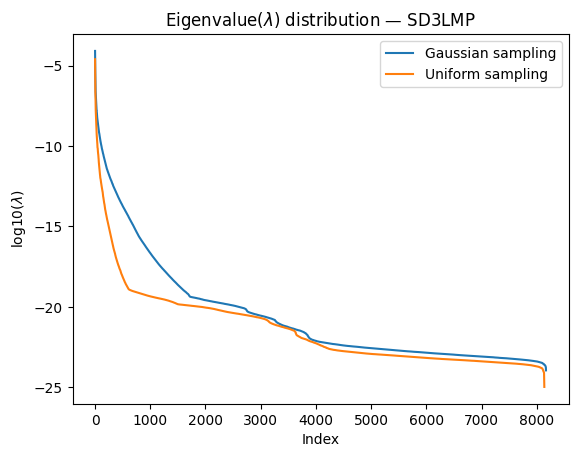

In [40]:
import matplotlib.pyplot as plt
import numpy as np

plt.plot(np.arange(d_gaus.shape[0]), np.log10(d_gaus), label="Gaussian sampling")
plt.plot(np.arange(d_uniform.shape[0]), np.log10(d_uniform), label="Uniform sampling")
plt.xlabel("Index")
plt.ylabel(r"log10($\lambda$)")
plt.title(r"Eigenvalue($\lambda$) distribution — SD3LMP")
plt.legend()

# Jacobian accuracies data.

In [41]:
r =          np.array([1,      5,      10,     20,     30,     40,     50,     60,     70,     80,     90,     100,    110,    120,    130,    140,    150])
J_uniform =  np.array([0.1989, 0.6427, 0.8179, 0.9034, 0.9422, 0.9651, 0.9756, 0.9835, 0.9890, 0.9919, 0.9938, 0.9951, 0.9961, 0.9969, 0.9974, 0.9979, 0.9983 ])
J_gaussian = np.array([0.1707, 0.5609, 0.7228 ,0.8214, 0.8647, 0.8937, 0.9142, 0.9294, 0.9406, 0.9493, 0.9567, 0.9624, 0.9671, 0.9715, 0.9751, 0.9781, 0.9808])

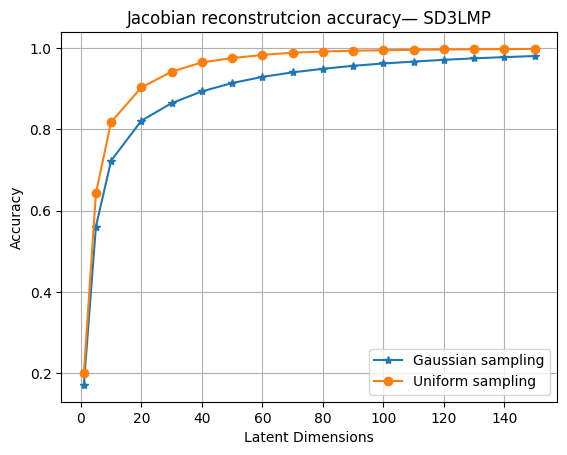

In [42]:
plt.plot(r, J_gaussian, marker='*', label="Gaussian sampling")
plt.plot(r, J_uniform, marker='o', label="Uniform sampling")
plt.ylabel("Accuracy")
plt.xlabel("Latent Dimensions")
plt.title("Jacobian reconstrutcion accuracy— SD3LMP")
plt.grid()
plt.legend()
plt.show()

# Sample size vs Accuracies (Gaussian)
| N | λ=0 L1 (500)| λ=0  H1 (500)| λ=1 L1 (500) | λ=1 H1 (500)| Stage L1 (250) | Stage H1 (250) | Stage L1 (500) | Stage H1 (500) |
|---|---------|---------|---------|---------|----------------|----------------|----------------|----------------|
| 2^6  |0.9853 |0.2183| 0.9570|0.4761 |0.9822 |0.0858 | 0.9033| 0.4555|
| 2^7  |0.9842 |0.3454 |0.9696 |0.4652 |0.9853 |0.1967 | 0.9751|0.4795 |
| 2^8  |0.9867 |0.4203| 0.9785| 0.4905| 0.9857 | 0.3631| 0.9487 |0.5164|
| 2^9  |0.9905|0.4242| 0.9705| 0.5323| 0.9897| 0.4328| 0.9637| 0.5868|
| 2^10 |0.9905|0.4242| 0.9798| 0.5353|0.9884 |0.4349|0.9540 | 0.6571|
| 2^11 |0.9909|0.4058| 0.9568| 0.5095|0.9831 |0.3904 |0.9574 |0.5950|
| 2^12 |0.9931 |0.4630 |0.9616 |0.5246 | 0.9936|0.5197| 0.9853| 0.7192|
| 2^13 |0.9910| 0.3912| 0.9606| 0.7367|0.9931|0.5763|0.9457| 0.7583|

# Sample size vs Accuracies (uniform)
| N | λ=0 L1(500)| λ=0 H1(500)| λ=1 L1(500)| λ=1 H1(500)| Stage L1(250) | Stage H1(250) | Stage L1(500) | Stage H1(500) |
|---|---------|---------|---------|---------|----------------|----------------|----------------|----------------|
| 2^6  |0.9892 |0.1235 | 0.9633|0.5793|0.9863| 0.0264|0.9834 |0.5677|
| 2^7  |0.9923 |0.3164 | 0.9765|0.6237|0.9893| 0.1217|0.9749 |0.5918|
| 2^8  |0.9934 |0.5432 | 0.9847|0.6119|0.9911| 0.2737|0.9709 |0.6237|
| 2^9  |0.9951 |0.5786 | 0.9831|0.6768|0.9920| 0.5649|0.9521 |0.7203|
| 2^10 |0.9964 |0.5759 | 0.9826|0.7244|0.9948| 0.5788|0.9825 |0.7372|
| 2^11 |0.9971 |0.5804 | 0.9872|0.7389|0.9970| 0.5802|0.9885 |0.7737|
| 2^12 |0.9965 |0.5765 | 0.9775|0.7366|0.9966| 0.5731|0.9902 |0.8746|
| 2^13 |0.9964 |0.5755 | 0.9862|0.7861|0.9969| 0.5757|0.9978 |0.9366|

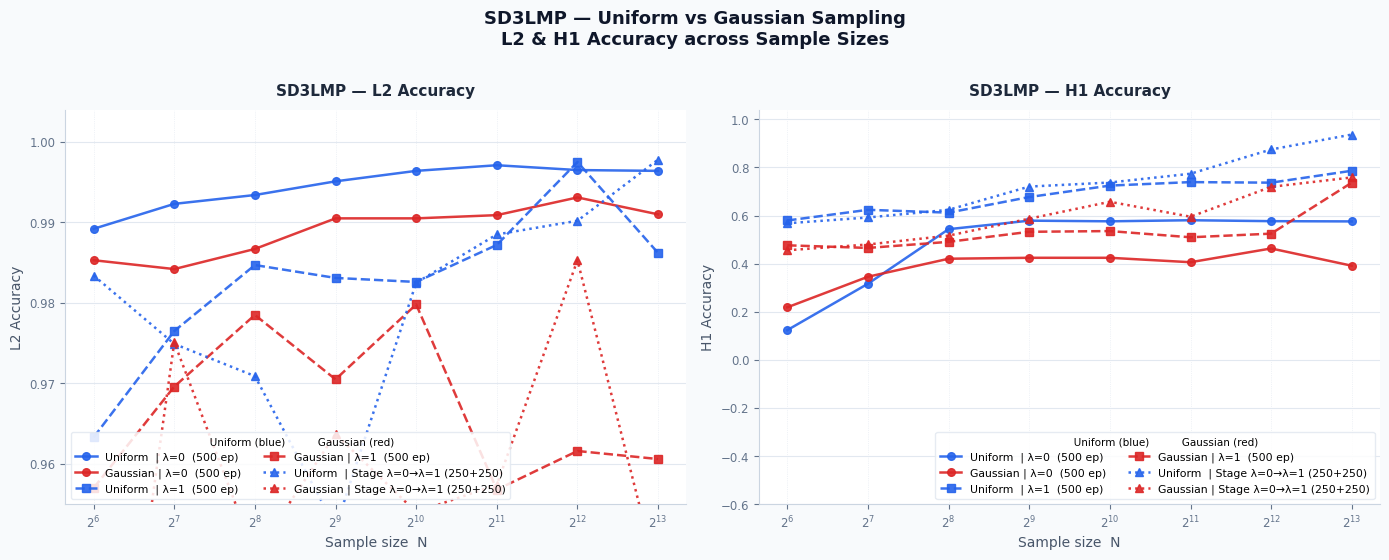

In [43]:
import numpy as np
import matplotlib.pyplot as plt

N_exp    = np.arange(6, 14)
x_labels = [f"$2^{{{i}}}$" for i in N_exp]
x        = np.arange(len(N_exp))

data = {
    "uniform": {
        "A_L2": [0.9892,0.9923,0.9934,0.9951,0.9964,0.9971,0.9965,0.9964], 
        "A_H1": [0.1235,0.3164,0.5432,0.5786,0.5759,0.5804,0.5765,0.5755],
        "B_L2": [0.9633,0.9765,0.9847,0.9831,0.9826,0.9872,0.9975,0.9862],
        "B_H1": [0.5793,0.6237,0.6119,0.6768,0.7244,0.7389,0.7366,0.7861],
        "C_L2": [0.9834,0.9749,0.9709,0.9521,0.9825,0.9885,0.9902,0.9978],
        "C_H1": [0.5677,0.5918,0.6237,0.7203,0.7372,0.7737,0.8746,0.9366],
    },
    "gaussian": {
        "A_L2": [0.9853,0.9842,0.9867,0.9905,0.9905,0.9909,0.9931,0.9910],
        "A_H1": [0.2183,0.3454,0.4203,0.4242,0.4242,0.4058,0.4630,0.3912],
        "B_L2": [0.9570,0.9696,0.9785,0.9705,0.9798,0.9568,0.9616,0.9606],
        "B_H1": [0.4761,0.4652,0.4905,0.5323,0.5353,0.5095,0.5246,0.7367],
        "C_L2": [0.9033,0.9751,0.9487,0.9637,0.9540,0.9574,0.9853,0.9457],
        "C_H1": [0.4555,0.4795,0.5164,0.5868,0.6571,0.5950,0.7192,0.7583],
    },
}

C_U = "#2563EB"   # blue  — uniform
C_G = "#DC2626"   # red   — gaussian

MODELS = [
    ("A", "λ=0  (500 ep)",           "-",  "o"),
    ("B", "λ=1  (500 ep)",           "--", "s"),
    ("C", "Stage λ=0→λ=1 (250+250)", ":",  "^"),
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor("#F8FAFC")

panel_cfg = [
    ("L2", "L2 Accuracy", (0.955, 1.004)),
    ("H1", "H1 Accuracy", (-0.60,  1.04)),
]

for ax, (metric, ylabel, ylim) in zip(axes, panel_cfg):
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.5, linestyle=":", zorder=0)
    ax.spines[["top","right"]].set_visible(False)
    ax.spines[["left","bottom"]].set_color("#CBD5E1")

    for m_key, m_label, ls, marker in MODELS:
        y_u = np.array(data["uniform"] [f"{m_key}_{metric}"])
        y_g = np.array(data["gaussian"][f"{m_key}_{metric}"])

        ax.plot(x, y_u, color=C_U, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Uniform  | {m_label}")
        ax.plot(x, y_g, color=C_G, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Gaussian | {m_label}")

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=9)
    ax.set_xlabel("Sample size  N", fontsize=10, color="#475569")
    ax.set_ylabel(ylabel, fontsize=10, color="#475569")
    ax.set_ylim(ylim)
    ax.tick_params(colors="#64748B", labelsize=8.5)
    ax.set_title(f"SD3LMP — {ylabel}", fontsize=11,
                 fontweight="bold", color="#1E293B", pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, ncol=2, fontsize=7.8,
              framealpha=0.85, edgecolor="#E2E8F0",
              loc="lower right" if metric == "H1" else "lower left",
              title="       Uniform (blue)          Gaussian (red)",
              title_fontsize=7.5)

fig.suptitle("SD3LMP — Uniform vs Gaussian Sampling\nL2 & H1 Accuracy across Sample Sizes",
             fontsize=13, fontweight="bold", color="#0F172A", y=1.01)

plt.tight_layout()
# plt.savefig("SD2LSP_L2_H1_comparison.png", dpi=160,
#             bbox_inches="tight", facecolor=fig.get_facecolor())
# plt.show()

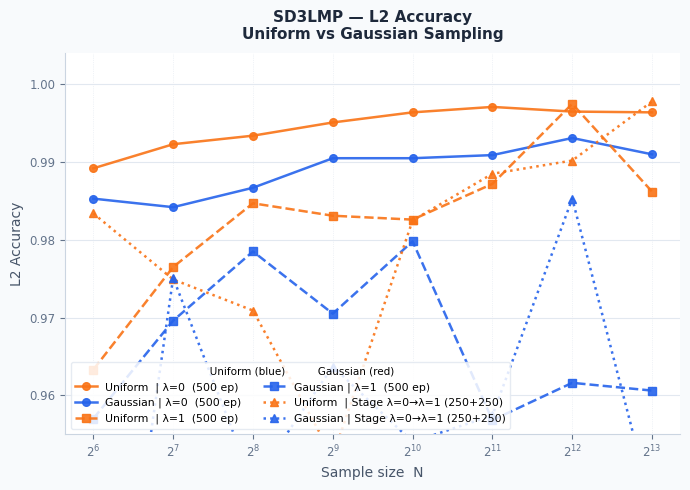

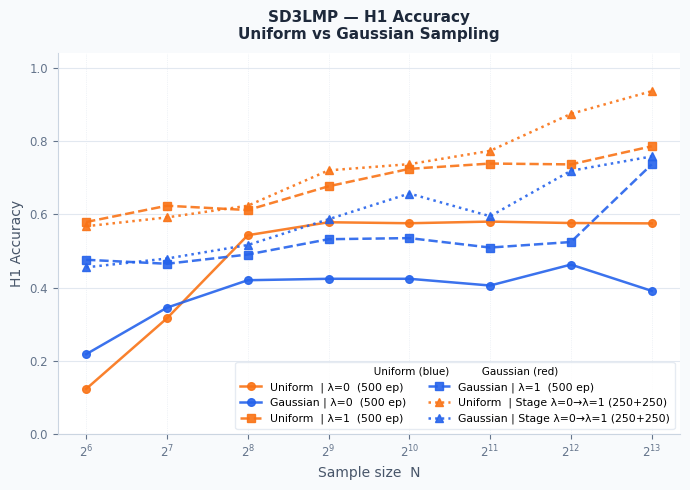

In [44]:
import numpy as np
import matplotlib.pyplot as plt

N_exp    = np.arange(6, 14)
x_labels = [f"$2^{{{i}}}$" for i in N_exp]
x        = np.arange(len(N_exp))

data = {
    "uniform": {
        "A_L2": [0.9892,0.9923,0.9934,0.9951,0.9964,0.9971,0.9965,0.9964], 
        "A_H1": [0.1235,0.3164,0.5432,0.5786,0.5759,0.5804,0.5765,0.5755],
        "B_L2": [0.9633,0.9765,0.9847,0.9831,0.9826,0.9872,0.9975,0.9862],
        "B_H1": [0.5793,0.6237,0.6119,0.6768,0.7244,0.7389,0.7366,0.7861],
        "C_L2": [0.9834,0.9749,0.9709,0.9521,0.9825,0.9885,0.9902,0.9978],
        "C_H1": [0.5677,0.5918,0.6237,0.7203,0.7372,0.7737,0.8746,0.9366],
    },
    "gaussian": {
        "A_L2": [0.9853,0.9842,0.9867,0.9905,0.9905,0.9909,0.9931,0.9910],
        "A_H1": [0.2183,0.3454,0.4203,0.4242,0.4242,0.4058,0.4630,0.3912],
        "B_L2": [0.9570,0.9696,0.9785,0.9705,0.9798,0.9568,0.9616,0.9606],
        "B_H1": [0.4761,0.4652,0.4905,0.5323,0.5353,0.5095,0.5246,0.7367],
        "C_L2": [0.9033,0.9751,0.9487,0.9637,0.9540,0.9574,0.9853,0.9457],
        "C_H1": [0.4555,0.4795,0.5164,0.5868,0.6571,0.5950,0.7192,0.7583],
    },
}

C_G = "#2563EB"   # blue  — gaussian
C_U = "#F97316"   # red   — uniform

MODELS = [
    ("A", "λ=0  (500 ep)",            "-",  "o"),
    ("B", "λ=1  (500 ep)",            "--", "s"),
    ("C", "Stage λ=0→λ=1 (250+250)",  ":",  "^"),
]

panel_cfg = [
    ("L2", "L2 Accuracy", (0.955, 1.004), "lower left",  "SD3LMP_L2.png"),
    ("H1", "H1 Accuracy", (-0.0,  1.04), "lower right", "SD3LMP_H1.png"),
]

for metric, ylabel, ylim, legend_loc, fname in panel_cfg:

    fig, ax = plt.subplots(figsize=(7, 5))
    fig.patch.set_facecolor("#F8FAFC")
    ax.set_facecolor("#FFFFFF")
    ax.grid(axis="y", color="#E2E8F0", linewidth=0.8, zorder=0)
    ax.grid(axis="x", color="#E2E8F0", linewidth=0.5, linestyle=":", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#CBD5E1")

    for m_key, m_label, ls, marker in MODELS:
        y_u = np.array(data["uniform"] [f"{m_key}_{metric}"])
        y_g = np.array(data["gaussian"][f"{m_key}_{metric}"])

        ax.plot(x, y_u, color=C_U, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Uniform  | {m_label}")
        ax.plot(x, y_g, color=C_G, linestyle=ls, marker=marker,
                markersize=5.5, linewidth=1.8, alpha=0.90,
                label=f"Gaussian | {m_label}")

    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, fontsize=9)
    ax.set_xlabel("Sample size  N", fontsize=10, color="#475569")
    ax.set_ylabel(ylabel, fontsize=10, color="#475569")
    ax.set_ylim(ylim)
    ax.tick_params(colors="#64748B", labelsize=8.5)
    ax.set_title(f"SD3LMP — {ylabel}\nUniform vs Gaussian Sampling",
                 fontsize=11, fontweight="bold", color="#1E293B", pad=10)

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, ncol=2, fontsize=7.8,
              framealpha=0.85, edgecolor="#E2E8F0",
              loc=legend_loc,
              title="       Uniform (blue)          Gaussian (red)",
              title_fontsize=7.5)

    plt.tight_layout()
    plt.savefig(fname, dpi=160, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()   # displays inline in the notebook
    plt.close()
    #print(f"Saved {fname}")

# Physical Coordinate with Uniform Sampling 
Phyiscal coordinates lies between [0.652, 0.748] 
Phyiscal coordinates lies between [0.652, 0.748]
Phyiscal coordinates lies between [0.652, 0.748]
Phyiscal coordinates lies between [0.156, 0.444]

# Inversion uniform observation (400), Noise= 5 %

# Initial coordinate

# 0.7, 0.7, 0.7, 0.1
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1 0.  0.7]
 [0.5 0.  0.7]
 [0.9 0.  0.7]
 [0.1 0.  0.3]
 [0.5 0.  0.1]
 [0.9 0.  0.3]]

[[0.1        0.         0.74799999]
 [0.5        0.         0.74799999]
 [0.9        0.         0.74799999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.24400001]
 [0.9        0.         0.3       ]]

[[ 0.1         0.          0.65200001]
 [ 0.5         0.          0.65200001]
 [ 0.9         0.          0.65200001]
 [ 0.1         0.          0.3       ]
 [ 0.5         0.         -0.04400001]
 [ 0.9         0.          0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 1.0371e-04, -4.3899e-05,  9.1790e-06,  1.7568e-05],
        [-4.3899e-05,  4.0535e-05,  5.5516e-05,  8.3547e-07],
        [ 9.1789e-06,  5.5516e-05,  2.6126e-04, -3.8279e-05],
        [ 1.7568e-05,  8.3547e-07, -3.8279e-05,  5.2536e-05]])

Prior mean:
tensor([ 0.1250,  0.1250,  0.1250, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0934,  0.1034,  0.1264, -0.1348])
Posterior std:
tensor([0.0102, 0.0064, 0.0162, 0.0072])

mean , mean + std , mean -std 

[[0.1        0.         0.62416408]
 [0.5        0.         0.64824617]
 [0.9        0.         0.70329318]
 [0.1        0.         0.3       ]
 [0.5        0.         0.07637274]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64860491]
 [0.5        0.         0.6635262 ]
 [0.9        0.         0.74208601]
 [0.1        0.         0.3       ]
 [0.5        0.         0.09376833]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.59972326]
 [0.5        0.         0.63296614]
 [0.9        0.         0.66450036]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05897715]
 [0.9        0.         0.3       ]]

# NUTS setting

Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1234) Posterior std:  tensor(0.0181)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0863) Posterior std:  tensor(0.0091)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0830) Posterior std:  tensor(0.0089)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1105) Posterior std:  tensor(0.0179)

mean , mean + std , mean -std 
[[0.1        0.         0.69627341]
 [0.5        0.         0.60709853]
 [0.9        0.         0.59915048]
 [0.1        0.         0.3       ]
 [0.5        0.         0.13478219]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73974906]
 [0.5        0.         0.62895254]
 [0.9        0.         0.62047994]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17779657]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65279776]
 [0.5        0.         0.58524451]
 [0.9        0.         0.57782101]
 [0.1        0.         0.3       ]
 [0.5        0.         0.0917678 ]
 [0.9        0.         0.3       ]]


# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1202),tensor(0.0186),tensor(0.1225),tensor(0.0920),tensor(0.1502),tensor(257.7015),tensor(1.0231)
mu_2,tensor(0.0866),tensor(0.0099),tensor(0.0871),tensor(0.0696),tensor(0.1018),tensor(189.9357),tensor(1.0142)
mu_3,tensor(0.0835),tensor(0.0085),tensor(0.0829),tensor(0.0699),tensor(0.0970),tensor(150.4897),tensor(1.0343)
mu_4,tensor(-0.1103),tensor(0.0171),tensor(-0.1104),tensor(-0.1369),tensor(-0.0806),tensor(230.0074),tensor(1.0203)


Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1202) Posterior std:  tensor(0.0186)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0866) Posterior std:  tensor(0.0099)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0835) Posterior std:  tensor(0.0085)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1103) Posterior std:  tensor(0.0171)

[[0.1        0.         0.68840066]
 [0.5        0.         0.60794959]
 [0.9        0.         0.600407  ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.13528607]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73308239]
 [0.5        0.         0.63170312]
 [0.9        0.         0.62069333]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17642341]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64371894]
 [0.5        0.         0.58419606]
 [0.9        0.         0.58012068]
 [0.1        0.         0.3       ]
 [0.5        0.         0.09414873]
 [0.9        0.         0.3       ]]


# 0.7, 0.7, 0.7, 0.2
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.69999999]
 [0.5        0.         0.69999999]
 [0.9        0.         0.69999999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20000001]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.748]
 [0.5   0.    0.748]
 [0.9   0.    0.748]
 [0.1   0.    0.3  ]
 [0.5   0.    0.344]
 [0.9   0.    0.3  ]]

[[0.1        0.         0.65199999]
 [0.5        0.         0.65199999]
 [0.9        0.         0.65199999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05600002]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 1.3693e-04, -3.1246e-05,  1.2985e-05,  5.4059e-05],
        [-3.1246e-05,  1.0837e-04, -3.4194e-05,  5.5477e-05],
        [ 1.2985e-05, -3.4194e-05,  1.2070e-04,  5.2977e-05],
        [ 5.4059e-05,  5.5477e-05,  5.2977e-05,  3.8341e-04]])

Prior mean:
tensor([ 0.1042,  0.1042,  0.1042, -0.1042], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0950,  0.0867,  0.0626, -0.1014])
Posterior std:
tensor([0.0117, 0.0104, 0.0110, 0.0196])

mean , mean + std , mean -std 

[[0.1        0.         0.67802448]
 [0.5        0.         0.6581465 ]
 [0.9        0.         0.60026858]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20673882]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70610839]
 [0.5        0.         0.68313078]
 [0.9        0.         0.62663594]
 [0.1        0.         0.3       ]
 [0.5        0.         0.25373275]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64994057]
 [0.5        0.         0.63316222]
 [0.9        0.         0.57390121]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15974489]
 [0.9        0.         0.3       ]]

# NUTS setting

Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1013) Posterior std:  tensor(0.0172)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0820) Posterior std:  tensor(0.0104)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0787) Posterior std:  tensor(0.0098)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0924) Posterior std:  tensor(0.0179)

mean , mean + std , mean -std 
[[0.1        0.         0.69303187]
 [0.5        0.         0.64675623]
 [0.9        0.         0.63896762]
 [0.1        0.         0.3       ]
 [0.5        0.         0.22823256]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73424705]
 [0.5        0.         0.67174132]
 [0.9        0.         0.6624893 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.27125625]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65181668]
 [0.5        0.         0.62177114]
 [0.9        0.         0.61544593]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18520887]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1002),tensor(0.0168),tensor(0.0976),tensor(0.0738),tensor(0.1287),tensor(304.3031),tensor(1.0154)
mu_2,tensor(0.0819),tensor(0.0101),tensor(0.0817),tensor(0.0654),tensor(0.0988),tensor(359.9079),tensor(1.0226)
mu_3,tensor(0.0789),tensor(0.0088),tensor(0.0789),tensor(0.0646),tensor(0.0933),tensor(434.3822),tensor(1.0133)
mu_4,tensor(-0.0934),tensor(0.0185),tensor(-0.0932),tensor(-0.1237),tensor(-0.0642),tensor(263.5823),tensor(1.0113)


Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1002) Posterior std:  tensor(0.0168)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0819) Posterior std:  tensor(0.0101)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0789) Posterior std:  tensor(0.0088)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0934) Posterior std:  tensor(0.0185)

[[0.1        0.         0.69036884]
 [0.5        0.         0.64656277]
 [0.9        0.         0.63931557]
 [0.1        0.         0.3       ]
 [0.5        0.         0.22582254]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73071889]
 [0.5        0.         0.6706965 ]
 [0.9        0.         0.6603265 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.27019077]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.6500188 ]
 [0.5        0.         0.62242905]
 [0.9        0.         0.61830464]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18145432]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.3
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 1.0774e-04, -3.0171e-05,  1.8004e-05,  4.4820e-05],
        [-3.0171e-05,  8.7336e-05, -3.2340e-05,  4.9492e-05],
        [ 1.8004e-05, -3.2340e-05,  1.1264e-04,  4.2730e-05],
        [ 4.4820e-05,  4.9492e-05,  4.2730e-05,  4.4147e-04]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0857,  0.0799,  0.0697, -0.0708])
Posterior std:
tensor([0.0104, 0.0093, 0.0106, 0.0210])

mean , mean + std , mean -std 

[[0.1        0.         0.70558301]
 [0.5        0.         0.69175023]
 [0.9        0.         0.66738631]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33002897]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73049492]
 [0.5        0.         0.71417911]
 [0.9        0.         0.69285796]
 [0.1        0.         0.3       ]
 [0.5        0.         0.38045589]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.6806711 ]
 [0.5        0.         0.66932135]
 [0.9        0.         0.64191466]
 [0.1        0.         0.3       ]
 [0.5        0.         0.27960204]
 [0.9        0.         0.3       ]]

# NUTS setting

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0852) Posterior std:  tensor(0.0132)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0759) Posterior std:  tensor(0.0091)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0751) Posterior std:  tensor(0.0094)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0697) Posterior std:  tensor(0.0175)

mean , mean + std , mean -std 
[[0.1        0.         0.70437839]
 [0.5        0.         0.68220562]
 [0.9        0.         0.68035527]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33272861]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73608544]
 [0.5        0.         0.70406961]
 [0.9        0.         0.70299362]
 [0.1        0.         0.3       ]
 [0.5        0.         0.37472573]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67267134]
 [0.5        0.         0.66034164]
 [0.9        0.         0.65771693]
 [0.1        0.         0.3       ]
 [0.5        0.         0.2907315 ]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0849),tensor(0.0136),tensor(0.0837),tensor(0.0612),tensor(0.1037),tensor(338.5962),tensor(1.0161)
mu_2,tensor(0.0779),tensor(0.0098),tensor(0.0780),tensor(0.0608),tensor(0.0934),tensor(331.3522),tensor(1.0110)
mu_3,tensor(0.0744),tensor(0.0099),tensor(0.0750),tensor(0.0586),tensor(0.0906),tensor(396.1245),tensor(1.0123)
mu_4,tensor(-0.0689),tensor(0.0189),tensor(-0.0690),tensor(-0.1002),tensor(-0.0398),tensor(348.2996),tensor(1.0119)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0849) Posterior std:  tensor(0.0136)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0779) Posterior std:  tensor(0.0098)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0744) Posterior std:  tensor(0.0099)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0689) Posterior std:  tensor(0.0189)

[[0.1        0.         0.70367529]
 [0.5        0.         0.68684729]
 [0.9        0.         0.67860134]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33474905]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73626527]
 [0.5        0.         0.7103834 ]
 [0.9        0.         0.70237746]
 [0.1        0.         0.3       ]
 [0.5        0.         0.38019942]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67108532]
 [0.5        0.         0.66331119]
 [0.9        0.         0.65482522]
 [0.1        0.         0.3       ]
 [0.5        0.         0.28929867]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.4
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399999]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.256]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 1.0436e-04, -3.3607e-05,  2.0864e-05,  2.2924e-05],
        [-3.3607e-05,  6.6541e-05, -3.6623e-05,  2.4432e-05],
        [ 2.0864e-05, -3.6623e-05,  1.1937e-04,  2.5636e-05],
        [ 2.2924e-05,  2.4432e-05,  2.5636e-05,  3.3647e-04]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0852,  0.0795,  0.0687, -0.0385], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0102, 0.0082, 0.0109, 0.0183])

mean , mean + std , mean -std 

[[0.1        0.         0.7044151 ]
 [0.5        0.         0.69075812]
 [0.9        0.         0.66476554]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40750385]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.72893296]
 [0.5        0.         0.71033559]
 [0.9        0.         0.69098666]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4515274 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67989724]
 [0.5        0.         0.67118064]
 [0.9        0.         0.63854443]
 [0.1        0.         0.3       ]
 [0.5        0.         0.3634803 ]
 [0.9        0.         0.3       ]]

# NUTS setting

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0851) Posterior std:  tensor(0.0125)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0784) Posterior std:  tensor(0.0100)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0730) Posterior std:  tensor(0.0103)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0180) Posterior std:  tensor(0.0386)

mean , mean + std , mean -std 
[[0.1        0.         0.70433558]
 [0.5        0.         0.68826033]
 [0.9        0.         0.67530578]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45681439]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.7343668 ]
 [0.5        0.         0.71229558]
 [0.9        0.         0.7000032 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54942098]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67430436]
 [0.5        0.         0.66422509]
 [0.9        0.         0.65060837]
 [0.1        0.         0.3       ]
 [0.5        0.         0.3642078 ]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0841),tensor(0.0132),tensor(0.0831),tensor(0.0631),tensor(0.1029),tensor(226.3689),tensor(1.0180)
mu_2,tensor(0.0794),tensor(0.0100),tensor(0.0796),tensor(0.0626),tensor(0.0959),tensor(193.8868),tensor(1.0178)
mu_3,tensor(0.0737),tensor(0.0105),tensor(0.0745),tensor(0.0565),tensor(0.0903),tensor(224.2161),tensor(1.0176)
mu_4,tensor(-0.0136),tensor(0.0393),tensor(-0.0244),tensor(-0.0657),tensor(0.0581),tensor(213.3619),tensor(1.0033)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0841) Posterior std:  tensor(0.0132)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0794) Posterior std:  tensor(0.0100)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0737) Posterior std:  tensor(0.0105)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0136) Posterior std:  tensor(0.0393)

[[0.1        0.         0.70183458]
 [0.5        0.         0.69044918]
 [0.9        0.         0.67676135]
 [0.1        0.         0.3       ]
 [0.5        0.         0.46734729]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73350388]
 [0.5        0.         0.71450647]
 [0.9        0.         0.70201218]
 [0.1        0.         0.3       ]
 [0.5        0.         0.56173277]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67016528]
 [0.5        0.         0.66639188]
 [0.9        0.         0.65151051]
 [0.1        0.         0.3       ]
 [0.5        0.         0.3729618 ]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.5
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.644     ]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.356]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 1.0311e-04, -3.5849e-05,  2.3942e-05,  1.5138e-05],
        [-3.5849e-05,  6.7425e-05, -3.8768e-05,  7.9810e-05],
        [ 2.3942e-05, -3.8768e-05,  1.2867e-04,  4.6508e-05],
        [ 1.5138e-05,  7.9810e-05,  4.6508e-05,  1.0627e-03]])

Prior mean:
tensor([0.0833, 0.0833, 0.0833, 0.0000], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([0.0860, 0.0820, 0.0697, 0.0215])
Posterior std:
tensor([0.0102, 0.0082, 0.0113, 0.0326])

mean , mean + std , mean -std 

[[0.1        0.         0.70648898]
 [0.5        0.         0.69683087]
 [0.9        0.         0.66726677]
 [0.1        0.         0.3       ]
 [0.5        0.         0.55152519]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73085891]
 [0.5        0.         0.71653792]
 [0.9        0.         0.69449059]
 [0.1        0.         0.3       ]
 [0.5        0.         0.62976136]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.68211906]
 [0.5        0.         0.67712382]
 [0.9        0.         0.64004296]
 [0.1        0.         0.3       ]
 [0.5        0.         0.47328901]
 [0.9        0.         0.3       ]]

# NUTS setting

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0866) Posterior std:  tensor(0.0128)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0789) Posterior std:  tensor(0.0099)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0740) Posterior std:  tensor(0.0106)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0389) Posterior std:  tensor(0.0401)

mean , mean + std , mean -std 
[[0.1        0.         0.70790575]
 [0.5        0.         0.68933522]
 [0.9        0.         0.67770606]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59333265]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73860598]
 [0.5        0.         0.71319474]
 [0.9        0.         0.70310633]
 [0.1        0.         0.3       ]
 [0.5        0.         0.68957497]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67720551]
 [0.5        0.         0.66547571]
 [0.9        0.         0.65230578]
 [0.1        0.         0.3       ]
 [0.5        0.         0.49709032]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0860),tensor(0.0122),tensor(0.0853),tensor(0.0670),tensor(0.1049),tensor(517.7925),tensor(1.0110)
mu_2,tensor(0.0791),tensor(0.0090),tensor(0.0795),tensor(0.0644),tensor(0.0944),tensor(502.1043),tensor(1.0068)
mu_3,tensor(0.0746),tensor(0.0104),tensor(0.0754),tensor(0.0578),tensor(0.0906),tensor(423.6081),tensor(1.0069)
mu_4,tensor(0.0415),tensor(0.0401),tensor(0.0345),tensor(-0.0165),tensor(0.1074),tensor(301.5244),tensor(1.0278)

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0860) Posterior std:  tensor(0.0122)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0791) Posterior std:  tensor(0.0090)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0746) Posterior std:  tensor(0.0104)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0415) Posterior std:  tensor(0.0401)

[[0.1        0.         0.70632644]
 [0.5        0.         0.68983309]
 [0.9        0.         0.67899316]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59951355]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73572445]
 [0.5        0.         0.71138119]
 [0.9        0.         0.70385773]
 [0.1        0.         0.3       ]
 [0.5        0.         0.69568464]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.67692843]
 [0.5        0.         0.668285  ]
 [0.9        0.         0.65412859]
 [0.1        0.         0.3       ]
 [0.5        0.         0.50334245]
 [0.9        0.         0.3       ]]

# Inversion uniform observation (400), Noise= 1 %

# Initial coordinate

# 0.7, 0.7, 0.7, 0.1
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1 0.  0.7]
 [0.5 0.  0.7]
 [0.9 0.  0.7]
 [0.1 0.  0.3]
 [0.5 0.  0.1]
 [0.9 0.  0.3]]

[[0.1        0.         0.74799999]
 [0.5        0.         0.74799999]
 [0.9        0.         0.74799999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.24400001]
 [0.9        0.         0.3       ]]

[[ 0.1         0.          0.65200001]
 [ 0.5         0.          0.65200001]
 [ 0.9         0.          0.65200001]
 [ 0.1         0.          0.3       ]
 [ 0.5         0.         -0.04400001]
 [ 0.9         0.          0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.9015e-06, -2.5766e-06,  3.8720e-07,  9.2376e-07],
        [-2.5766e-06,  3.1204e-06,  6.9362e-06, -7.1623e-07],
        [ 3.8718e-07,  6.9362e-06,  3.0641e-05, -4.3772e-06],
        [ 9.2377e-07, -7.1623e-07, -4.3772e-06,  2.5772e-06]])

Prior mean:
tensor([ 0.1250,  0.1250,  0.1250, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.1014,  0.0961,  0.1149, -0.1378])
Posterior std:
tensor([0.0024, 0.0018, 0.0055, 0.0016])

mean , mean + std , mean -std 

[[0.1        0.         0.64341805]
 [0.5        0.         0.63063078]
 [0.9        0.         0.67566081]
 [0.1        0.         0.3       ]
 [0.5        0.         0.06928166]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64924837]
 [0.5        0.         0.63487033]
 [0.9        0.         0.68894583]
 [0.1        0.         0.3       ]
 [0.5        0.         0.07313453]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.63758773]
 [0.5        0.         0.62639123]
 [0.9        0.         0.6623758 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.06542879]
 [0.9        0.         0.3       ]]

# NUTS setting

mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0852),tensor(0.0023),tensor(0.0853),tensor(0.0813),tensor(0.0889),tensor(157.3741),tensor(1.0340)
mu_2,tensor(0.0812),tensor(0.0025),tensor(0.0812),tensor(0.0771),tensor(0.0855),tensor(96.3686),tensor(1.0531)
mu_3,tensor(0.0811),tensor(0.0023),tensor(0.0812),tensor(0.0775),tensor(0.0850),tensor(113.4504),tensor(1.0564)
mu_4,tensor(-0.1573),tensor(0.0047),tensor(-0.1572),tensor(-0.1655),tensor(-0.1506),tensor(71.3393),tensor(1.0703)


Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0852) Posterior std:  tensor(0.0023)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0812) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0811) Posterior std:  tensor(0.0023)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1573) Posterior std:  tensor(0.0047)

mean , mean + std , mean -std 
[[0.1        0.         0.60440537]
 [0.5        0.         0.5948632 ]
 [0.9        0.         0.59475961]
 [0.1        0.         0.3       ]
 [0.5        0.         0.02251971]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.60984189]
 [0.5        0.         0.60094632]
 [0.9        0.         0.60025223]
 [0.1        0.         0.3       ]
 [0.5        0.         0.03384955]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.59896885]
 [0.5        0.         0.58878008]
 [0.9        0.         0.58926699]
 [0.1        0.         0.3       ]
 [0.5        0.         0.01118987]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0848),tensor(0.0026),tensor(0.0848),tensor(0.0806),tensor(0.0889),tensor(139.3816),tensor(1.0426)
mu_2,tensor(0.0814),tensor(0.0024),tensor(0.0815),tensor(0.0775),tensor(0.0853),tensor(182.4857),tensor(1.0193)
mu_3,tensor(0.0808),tensor(0.0024),tensor(0.0810),tensor(0.0769),tensor(0.0851),tensor(175.1356),tensor(1.0172)
mu_4,tensor(-0.1576),tensor(0.0042),tensor(-0.1577),tensor(-0.1643),tensor(-0.1505),tensor(182.4515),tensor(1.0339)


Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0848) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0814) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0808) Posterior std:  tensor(0.0024)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1576) Posterior std:  tensor(0.0042)

[[0.1        0.         0.60363397]
 [0.5        0.         0.59533947]
 [0.9        0.         0.59403535]
 [0.1        0.         0.3       ]
 [0.5        0.         0.02171344]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.60989562]
 [0.5        0.         0.60111269]
 [0.9        0.         0.59990766]
 [0.1        0.         0.3       ]
 [0.5        0.         0.03170822]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.59737232]
 [0.5        0.         0.58956626]
 [0.9        0.         0.58816303]
 [0.1        0.         0.3       ]
 [0.5        0.         0.01171865]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.2
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.69999999]
 [0.5        0.         0.69999999]
 [0.9        0.         0.69999999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20000001]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.748]
 [0.5   0.    0.748]
 [0.9   0.    0.748]
 [0.1   0.    0.3  ]
 [0.5   0.    0.344]
 [0.9   0.    0.3  ]]

[[0.1        0.         0.65199999]
 [0.5        0.         0.65199999]
 [0.9        0.         0.65199999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05600002]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 8.5981e-06, -2.6559e-06,  1.4842e-06,  3.4675e-06],
        [-2.6559e-06,  6.4847e-06, -2.7383e-06,  2.6619e-06],
        [ 1.4842e-06, -2.7383e-06,  7.2420e-06,  3.1944e-06],
        [ 3.4675e-06,  2.6619e-06,  3.1944e-06,  1.8431e-05]])

Prior mean:
tensor([ 0.1042,  0.1042,  0.1042, -0.1042], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0827,  0.0819,  0.0743, -0.1228])
Posterior std:
tensor([0.0029, 0.0025, 0.0027, 0.0043])

mean , mean + std , mean -std 

[[0.1        0.         0.64854702]
 [0.5        0.         0.64648086]
 [0.9        0.         0.62843944]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15536724]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65558442]
 [0.5        0.         0.65259247]
 [0.9        0.         0.6348981 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16567082]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64150962]
 [0.5        0.         0.64036925]
 [0.9        0.         0.62198079]
 [0.1        0.         0.3       ]
 [0.5        0.         0.14506366]
 [0.9        0.         0.3       ]]

# NUTS setting
mu_1,tensor(0.0847),tensor(0.0028),tensor(0.0848),tensor(0.0799),tensor(0.0890),tensor(91.8434),tensor(1.0589)
mu_2,tensor(0.0814),tensor(0.0024),tensor(0.0813),tensor(0.0775),tensor(0.0851),tensor(97.3560),tensor(1.0535)
mu_3,tensor(0.0807),tensor(0.0027),tensor(0.0808),tensor(0.0765),tensor(0.0851),tensor(102.0682),tensor(1.0508)
mu_4,tensor(-0.1174),tensor(0.0042),tensor(-0.1176),tensor(-0.1242),tensor(-0.1103),tensor(73.7601),tensor(1.0531)

Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0847) Posterior std:  tensor(0.0028)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0814) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0807) Posterior std:  tensor(0.0027)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1174) Posterior std:  tensor(0.0042)

mean , mean + std , mean -std 
[[0.1        0.         0.65324689]
 [0.5        0.         0.64529666]
 [0.9        0.         0.64371645]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16816183]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65985385]
 [0.5        0.         0.65104992]
 [0.9        0.         0.65013713]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17820521]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64663994]
 [0.5        0.         0.63954341]
 [0.9        0.         0.63729576]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15811845]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0844),tensor(0.0025),tensor(0.0845),tensor(0.0804),tensor(0.0885),tensor(207.9834),tensor(1.0276)
mu_2,tensor(0.0815),tensor(0.0024),tensor(0.0816),tensor(0.0775),tensor(0.0851),tensor(216.2493),tensor(1.0215)
mu_3,tensor(0.0804),tensor(0.0026),tensor(0.0804),tensor(0.0760),tensor(0.0844),tensor(176.2842),tensor(1.0157)
mu_4,tensor(-0.1184),tensor(0.0041),tensor(-0.1183),tensor(-0.1246),tensor(-0.1113),tensor(143.1758),tensor(1.0304)

Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0844) Posterior std:  tensor(0.0025)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0815) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0804) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1184) Posterior std:  tensor(0.0041)

[[0.1        0.         0.65245991]
 [0.5        0.         0.64566563]
 [0.9        0.         0.64290799]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16595151]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65834529]
 [0.5        0.         0.65133948]
 [0.9        0.         0.64903702]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17570793]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64657454]
 [0.5        0.         0.63999177]
 [0.9        0.         0.63677897]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15619508]
 [0.9        0.         0.3       ]]


# 0.7, 0.7, 0.7, 0.3
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 6.1665e-06, -2.2071e-06,  1.6287e-06,  2.6760e-06],
        [-2.2071e-06,  4.8959e-06, -2.3875e-06,  2.3563e-06],
        [ 1.6287e-06, -2.3875e-06,  6.5656e-06,  2.5776e-06],
        [ 2.6760e-06,  2.3563e-06,  2.5776e-06,  2.0958e-05]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0848,  0.0817,  0.0802, -0.0788])
Posterior std:
tensor([0.0025, 0.0022, 0.0026, 0.0046])

mean , mean + std , mean -std 

[[0.1        0.         0.70348763]
 [0.5        0.         0.69608622]
 [0.9        0.         0.69254881]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31081573]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70944741]
 [0.5        0.         0.7013966 ]
 [0.9        0.         0.69869842]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32180297]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69752785]
 [0.5        0.         0.69077584]
 [0.9        0.         0.6863992 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29982849]
 [0.9        0.         0.3       ]]

# NUTS setting
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0837),tensor(0.0026),tensor(0.0838),tensor(0.0797),tensor(0.0879),tensor(78.8105),tensor(1.0372)
mu_2,tensor(0.0808),tensor(0.0023),tensor(0.0809),tensor(0.0769),tensor(0.0846),tensor(76.8984),tensor(1.0813)
mu_3,tensor(0.0801),tensor(0.0026),tensor(0.0801),tensor(0.0759),tensor(0.0843),tensor(74.0406),tensor(1.0563)
mu_4,tensor(-0.0787),tensor(0.0039),tensor(-0.0785),tensor(-0.0853),tensor(-0.0725),tensor(43.6895),tensor(1.1424)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0837) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0808) Posterior std:  tensor(0.0023)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0801) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0787) Posterior std:  tensor(0.0039)

mean , mean + std , mean -std 
[[0.1        0.         0.70084519]
 [0.5        0.         0.69398692]
 [0.9        0.         0.69222324]
 [0.1        0.         0.3       ]
 [0.5        0.         0.3112093 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70698687]
 [0.5        0.         0.69954622]
 [0.9        0.         0.69844721]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32057404]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69470351]
 [0.5        0.         0.68842762]
 [0.9        0.         0.68599928]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30184457]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0842),tensor(0.0026),tensor(0.0843),tensor(0.0803),tensor(0.0887),tensor(213.5494),tensor(1.0059)
mu_2,tensor(0.0807),tensor(0.0024),tensor(0.0809),tensor(0.0769),tensor(0.0847),tensor(205.4609),tensor(1.0188)
mu_3,tensor(0.0800),tensor(0.0024),tensor(0.0800),tensor(0.0761),tensor(0.0840),tensor(219.0700),tensor(1.0105)
mu_4,tensor(-0.0786),tensor(0.0042),tensor(-0.0787),tensor(-0.0858),tensor(-0.0720),tensor(142.6003),tensor(1.0419)

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0842) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0807) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0800) Posterior std:  tensor(0.0024)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0786) Posterior std:  tensor(0.0042)

[[0.1        0.         0.7020974 ]
 [0.5        0.         0.69374273]
 [0.9        0.         0.69190079]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31140528]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70824672]
 [0.5        0.         0.69948732]
 [0.9        0.         0.6977582 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32152438]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69594809]
 [0.5        0.         0.68799814]
 [0.9        0.         0.68604338]
 [0.1        0.         0.3       ]
 [0.5        0.         0.30128618]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.4
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399999]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.256]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.9607e-06, -2.3593e-06,  1.8915e-06,  1.3435e-06],
        [-2.3593e-06,  3.6801e-06, -2.6625e-06,  9.8811e-07],
        [ 1.8915e-06, -2.6625e-06,  7.1672e-06,  1.5537e-06],
        [ 1.3435e-06,  9.8811e-07,  1.5537e-06,  1.5035e-05]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417])
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0846,  0.0817,  0.0801, -0.0382])
Posterior std:
tensor([0.0024, 0.0019, 0.0027, 0.0039])

mean , mean + std , mean -std 

[[0.1        0.         0.7031292 ]
 [0.5        0.         0.69605206]
 [0.9        0.         0.69217439]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40840335]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70898866]
 [0.5        0.         0.70065613]
 [0.9        0.         0.69859961]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41770945]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69726973]
 [0.5        0.         0.691448  ]
 [0.9        0.         0.68574918]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39909725]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0846),tensor(0.0027),tensor(0.0847),tensor(0.0800),tensor(0.0888),tensor(137.8923),tensor(1.0322)
mu_2,tensor(0.0797),tensor(0.0026),tensor(0.0799),tensor(0.0754),tensor(0.0842),tensor(103.2519),tensor(1.0520)
mu_3,tensor(0.0802),tensor(0.0026),tensor(0.0803),tensor(0.0758),tensor(0.0842),tensor(87.8364),tensor(1.0334)
mu_4,tensor(-0.0380),tensor(0.0038),tensor(-0.0381),tensor(-0.0440),tensor(-0.0316),tensor(81.0950),tensor(1.0696)

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0846) Posterior std:  tensor(0.0027)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0797) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0802) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0380) Posterior std:  tensor(0.0038)

mean , mean + std , mean -std 
[[0.1        0.         0.70311915]
 [0.5        0.         0.6913404 ]
 [0.9        0.         0.69250947]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40879791]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70948927]
 [0.5        0.         0.69766423]
 [0.9        0.         0.69881685]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41800378]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69674903]
 [0.5        0.         0.68501658]
 [0.9        0.         0.6862021 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39959204]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0841),tensor(0.0026),tensor(0.0843),tensor(0.0797),tensor(0.0883),tensor(193.9280),tensor(1.0241)
mu_2,tensor(0.0801),tensor(0.0027),tensor(0.0803),tensor(0.0755),tensor(0.0842),tensor(122.4596),tensor(1.0350)
mu_3,tensor(0.0802),tensor(0.0026),tensor(0.0802),tensor(0.0760),tensor(0.0845),tensor(286.6892),tensor(1.0109)
mu_4,tensor(-0.0382),tensor(0.0040),tensor(-0.0381),tensor(-0.0448),tensor(-0.0317),tensor(136.0220),tensor(1.0367)

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0841) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0801) Posterior std:  tensor(0.0027)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0802) Posterior std:  tensor(0.0026)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0382) Posterior std:  tensor(0.0040)

[[0.1        0.         0.70188288]
 [0.5        0.         0.69225187]
 [0.9        0.         0.6925113 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4082607 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70820242]
 [0.5        0.         0.69861234]
 [0.9        0.         0.69875609]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41777374]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69556334]
 [0.5        0.         0.68589141]
 [0.9        0.         0.6862665 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.39874766]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.5
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.644     ]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.356]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.9471e-06, -2.5490e-06,  2.2376e-06,  8.1364e-07],
        [-2.5490e-06,  3.9258e-06, -2.8956e-06,  4.9238e-06],
        [ 2.2376e-06, -2.8956e-06,  8.0793e-06,  3.1939e-06],
        [ 8.1364e-07,  4.9238e-06,  3.1939e-06,  6.1169e-05]])

Prior mean:
tensor([0.0833, 0.0833, 0.0833, 0.0000], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([0.0850, 0.0840, 0.0809, 0.0181], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0024, 0.0020, 0.0028, 0.0078])

mean , mean + std , mean -std 

[[0.1        0.         0.70408839]
 [0.5        0.         0.70151166]
 [0.9        0.         0.69406081]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54339242]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70994117]
 [0.5        0.         0.70626693]
 [0.9        0.         0.70088261]
 [0.1        0.         0.3       ]
 [0.5        0.         0.56216301]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69823561]
 [0.5        0.         0.69675639]
 [0.9        0.         0.687239  ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.52462183]
 [0.9        0.         0.3       ]]

# NUTS setting
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0852),tensor(0.0026),tensor(0.0852),tensor(0.0806),tensor(0.0890),tensor(73.2561),tensor(1.0836)
mu_2,tensor(0.0827),tensor(0.0029),tensor(0.0831),tensor(0.0780),tensor(0.0871),tensor(31.7688),tensor(1.1721)
mu_3,tensor(0.0805),tensor(0.0027),tensor(0.0805),tensor(0.0762),tensor(0.0851),tensor(113.6028),tensor(1.0408)
mu_4,tensor(0.0217),tensor(0.0123),tensor(0.0202),tensor(0.0025),tensor(0.0392),tensor(15.6677),tensor(1.5924)



Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0852) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0827) Posterior std:  tensor(0.0029)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0805) Posterior std:  tensor(0.0027)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0217) Posterior std:  tensor(0.0123)

mean , mean + std , mean -std 
[[0.1        0.         0.70439897]
 [0.5        0.         0.69843969]
 [0.9        0.         0.69322897]
 [0.1        0.         0.3       ]
 [0.5        0.         0.55203231]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71068063]
 [0.5        0.         0.70532716]
 [0.9        0.         0.69974638]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58145031]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69811731]
 [0.5        0.         0.69155223]
 [0.9        0.         0.68671156]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5226143 ]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0852),tensor(0.0022),tensor(0.0852),tensor(0.0815),tensor(0.0887),tensor(250.6714),tensor(1.0106)
mu_2,tensor(0.0825),tensor(0.0026),tensor(0.0828),tensor(0.0780),tensor(0.0865),tensor(183.0767),tensor(1.0176)
mu_3,tensor(0.0810),tensor(0.0026),tensor(0.0810),tensor(0.0766),tensor(0.0852),tensor(271.0834),tensor(1.0135)
mu_4,tensor(0.0219),tensor(0.0119),tensor(0.0213),tensor(0.0029),tensor(0.0414),tensor(78.5104),tensor(1.0641)

Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0852) Posterior std:  tensor(0.0022)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0825) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0810) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0219) Posterior std:  tensor(0.0119)

[[0.1        0.         0.70444992]
 [0.5        0.         0.69792732]
 [0.9        0.         0.69444356]
 [0.1        0.         0.3       ]
 [0.5        0.         0.55262875]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70971579]
 [0.5        0.         0.70424456]
 [0.9        0.         0.70071839]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58130698]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69918404]
 [0.5        0.         0.69161008]
 [0.9        0.         0.68816872]
 [0.1        0.         0.3       ]
 [0.5        0.         0.52395051]
 [0.9        0.         0.3       ]]

# Physical Coordinate with Non Uniform Sampling 
Phyiscal coordinates lies between [0.652, 0.748] 
Phyiscal coordinates lies between [0.652, 0.748]
Phyiscal coordinates lies between [0.652, 0.748]
Phyiscal coordinates lies between [0.156, 0.444]

# Inversion non uniform observation (400), Noise= 5 %

# Initial coordinate

# 0.7, 0.7, 0.7, 0.1
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1 0.  0.7]
 [0.5 0.  0.7]
 [0.9 0.  0.7]
 [0.1 0.  0.3]
 [0.5 0.  0.1]
 [0.9 0.  0.3]]

[[0.1        0.         0.74799999]
 [0.5        0.         0.74799999]
 [0.9        0.         0.74799999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.24400001]
 [0.9        0.         0.3       ]]

[[ 0.1         0.          0.65200001]
 [ 0.5         0.          0.65200001]
 [ 0.9         0.          0.65200001]
 [ 0.1         0.          0.3       ]
 [ 0.5         0.         -0.04400001]
 [ 0.9         0.          0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 6.2707e-05, -2.9075e-05, -3.3857e-06,  8.7705e-06],
        [-2.9075e-05,  2.8648e-05,  3.9791e-05,  6.4838e-06],
        [-3.3857e-06,  3.9791e-05,  1.6679e-04, -2.4901e-05],
        [ 8.7705e-06,  6.4838e-06, -2.4901e-05,  5.4217e-05]])

Prior mean:
tensor([ 0.1250,  0.1250,  0.1250, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.1020,  0.0997,  0.1186, -0.1301], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0079, 0.0054, 0.0129, 0.0074])

mean , mean + std , mean -std 

[[0.1        0.         0.64472366]
 [0.5        0.         0.63930715]
 [0.9        0.         0.6845457 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.08769474]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.66372879]
 [0.5        0.         0.65215291]
 [0.9        0.         0.71554068]
 [0.1        0.         0.3       ]
 [0.5        0.         0.10536644]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.62571853]
 [0.5        0.         0.62646139]
 [0.9        0.         0.65355072]
 [0.1        0.         0.3       ]
 [0.5        0.         0.07002302]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1119),tensor(0.0181),tensor(0.1067),tensor(0.0870),tensor(0.1423),tensor(40.7057),tensor(1.1410)
mu_2,tensor(0.0886),tensor(0.0082),tensor(0.0890),tensor(0.0753),tensor(0.1009),tensor(109.1771),tensor(1.0445)
mu_3,tensor(0.0932),tensor(0.0084),tensor(0.0930),tensor(0.0798),tensor(0.1073),tensor(43.7323),tensor(1.0558)
mu_4,tensor(-0.1099),tensor(0.0219),tensor(-0.1078),tensor(-0.1484),tensor(-0.0757),tensor(35.8526),tensor(1.1122)


Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1119) Posterior std:  tensor(0.0181)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0886) Posterior std:  tensor(0.0082)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0932) Posterior std:  tensor(0.0084)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1099) Posterior std:  tensor(0.0219)

mean , mean + std , mean -std 
[[0.1        0.         0.66867534]
 [0.5        0.         0.61271452]
 [0.9        0.         0.6237893 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.13630146]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71217938]
 [0.5        0.         0.63240808]
 [0.9        0.         0.64393153]
 [0.1        0.         0.3       ]
 [0.5        0.         0.1889152 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.6251713 ]
 [0.5        0.         0.59302095]
 [0.9        0.         0.60364708]
 [0.1        0.         0.3       ]
 [0.5        0.         0.08368773]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1091),tensor(0.0173),tensor(0.1044),tensor(0.0839),tensor(0.1379),tensor(67.4144),tensor(1.0284)
mu_2,tensor(0.0876),tensor(0.0080),tensor(0.0876),tensor(0.0752),tensor(0.1007),tensor(161.3737),tensor(1.0250)
mu_3,tensor(0.0926),tensor(0.0071),tensor(0.0926),tensor(0.0804),tensor(0.1031),tensor(200.6818),tensor(1.0288)
mu_4,tensor(-0.1129),tensor(0.0212),tensor(-0.1129),tensor(-0.1431),tensor(-0.0728),tensor(125.0466),tensor(1.0331)

Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1091) Posterior std:  tensor(0.0173)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0876) Posterior std:  tensor(0.0080)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0926) Posterior std:  tensor(0.0071)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1129) Posterior std:  tensor(0.0212)

[[0.1        0.         0.6618574 ]
 [0.5        0.         0.61032678]
 [0.9        0.         0.62234769]
 [0.1        0.         0.3       ]
 [0.5        0.         0.12900661]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70349676]
 [0.5        0.         0.62955302]
 [0.9        0.         0.63937487]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17991074]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.62021803]
 [0.5        0.         0.59110053]
 [0.9        0.         0.60532051]
 [0.1        0.         0.3       ]
 [0.5        0.         0.07810248]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.2
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.69999999]
 [0.5        0.         0.69999999]
 [0.9        0.         0.69999999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20000001]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.748]
 [0.5   0.    0.748]
 [0.9   0.    0.748]
 [0.1   0.    0.3  ]
 [0.5   0.    0.344]
 [0.9   0.    0.3  ]]

[[0.1        0.         0.65199999]
 [0.5        0.         0.65199999]
 [0.9        0.         0.65199999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05600002]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 8.1048e-05, -1.7952e-05,  9.5364e-06,  5.4593e-05],
        [-1.7952e-05,  6.6072e-05, -1.9402e-05,  2.8564e-05],
        [ 9.5364e-06, -1.9402e-05,  7.0238e-05,  5.3157e-05],
        [ 5.4593e-05,  2.8564e-05,  5.3157e-05,  4.5778e-04]])

Prior mean:
tensor([ 0.1042,  0.1042,  0.1042, -0.1042], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0924,  0.0861,  0.0836, -0.0971], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0090, 0.0081, 0.0084, 0.0214])

mean , mean + std , mean -std 

[[0.1        0.         0.67173361]
 [0.5        0.         0.65659318]
 [0.9        0.         0.65057924]
 [0.1        0.         0.3       ]
 [0.5        0.         0.21684905]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.69334002]
 [0.5        0.         0.67610155]
 [0.9        0.         0.67069319]
 [0.1        0.         0.3       ]
 [0.5        0.         0.26819919]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.6501272 ]
 [0.5        0.         0.63708481]
 [0.9        0.         0.63046528]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16549891]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0966),tensor(0.0098),tensor(0.0955),tensor(0.0816),tensor(0.1132),tensor(95.1523),tensor(1.0372)
mu_2,tensor(0.0865),tensor(0.0079),tensor(0.0864),tensor(0.0735),tensor(0.0990),tensor(143.4367),tensor(1.0460)
mu_3,tensor(0.0888),tensor(0.0083),tensor(0.0896),tensor(0.0743),tensor(0.1015),tensor(131.1119),tensor(1.0249)
mu_4,tensor(-0.0887),tensor(0.0187),tensor(-0.0883),tensor(-0.1167),tensor(-0.0560),tensor(71.6393),tensor(1.0799)


Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0966) Posterior std:  tensor(0.0098)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0865) Posterior std:  tensor(0.0079)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0888) Posterior std:  tensor(0.0083)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0887) Posterior std:  tensor(0.0187)

mean , mean + std , mean -std 
[[0.1        0.         0.68187835]
 [0.5        0.         0.6575295 ]
 [0.9        0.         0.66303812]
 [0.1        0.         0.3       ]
 [0.5        0.         0.23723179]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70549774]
 [0.5        0.         0.67659081]
 [0.9        0.         0.68301468]
 [0.1        0.         0.3       ]
 [0.5        0.         0.28219114]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65825895]
 [0.5        0.         0.6384682 ]
 [0.9        0.         0.64306155]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19227243]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1001),tensor(0.0124),tensor(0.0979),tensor(0.0809),tensor(0.1201),tensor(89.8800),tensor(1.0485)
mu_2,tensor(0.0855),tensor(0.0084),tensor(0.0856),tensor(0.0719),tensor(0.0991),tensor(252.6544),tensor(1.0133)
mu_3,tensor(0.0901),tensor(0.0086),tensor(0.0906),tensor(0.0740),tensor(0.1015),tensor(187.5110),tensor(1.0238)
mu_4,tensor(-0.0868),tensor(0.0194),tensor(-0.0855),tensor(-0.1209),tensor(-0.0582),tensor(167.0529),tensor(1.0352)


Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1001) Posterior std:  tensor(0.0124)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0855) Posterior std:  tensor(0.0084)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0901) Posterior std:  tensor(0.0086)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0868) Posterior std:  tensor(0.0194)

[[0.1        0.         0.690324  ]
 [0.5        0.         0.65521676]
 [0.9        0.         0.66621802]
 [0.1        0.         0.3       ]
 [0.5        0.         0.2417887 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.72005794]
 [0.5        0.         0.67533702]
 [0.9        0.         0.68689239]
 [0.1        0.         0.3       ]
 [0.5        0.         0.28834686]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.66059005]
 [0.5        0.         0.6350965 ]
 [0.9        0.         0.64554365]
 [0.1        0.         0.3       ]
 [0.5        0.         0.19523054]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.3
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.5061e-05, -1.6156e-05,  1.0465e-05,  3.9307e-05],
        [-1.6156e-05,  4.8699e-05, -1.7346e-05,  4.9202e-06],
        [ 1.0465e-05, -1.7346e-05,  5.7952e-05,  3.8056e-05],
        [ 3.9307e-05,  4.9202e-06,  3.8056e-05,  4.5334e-04]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0942,  0.0850,  0.0894, -0.0521], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0074, 0.0070, 0.0076, 0.0213])

mean , mean + std , mean -std 

[[0.1        0.         0.72602654]
 [0.5        0.         0.70391653]
 [0.9        0.         0.71445252]
 [0.1        0.         0.3       ]
 [0.5        0.         0.37503993]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74383526]
 [0.5        0.         0.72066485]
 [0.9        0.         0.73272278]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4261401 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70821781]
 [0.5        0.         0.68716821]
 [0.9        0.         0.69618226]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32393976]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0932),tensor(0.0069),tensor(0.0930),tensor(0.0814),tensor(0.1037),tensor(148.7625),tensor(1.0181)
mu_2,tensor(0.0840),tensor(0.0074),tensor(0.0845),tensor(0.0713),tensor(0.0953),tensor(164.0431),tensor(1.0239)
mu_3,tensor(0.0868),tensor(0.0074),tensor(0.0873),tensor(0.0751),tensor(0.0988),tensor(129.8381),tensor(1.0335)
mu_4,tensor(-0.0578),tensor(0.0169),tensor(-0.0569),tensor(-0.0850),tensor(-0.0302),tensor(169.8494),tensor(1.0650)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0932) Posterior std:  tensor(0.0069)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0840) Posterior std:  tensor(0.0074)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0868) Posterior std:  tensor(0.0074)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0578) Posterior std:  tensor(0.0169)

mean , mean + std , mean -std 
[[0.1        0.         0.72366848]
 [0.5        0.         0.70160348]
 [0.9        0.         0.70836051]
 [0.1        0.         0.3       ]
 [0.5        0.         0.36125658]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74030996]
 [0.5        0.         0.71925012]
 [0.9        0.         0.72610571]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40183022]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.707027  ]
 [0.5        0.         0.68395685]
 [0.9        0.         0.6906153 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32068294]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0933),tensor(0.0084),tensor(0.0928),tensor(0.0797),tensor(0.1050),tensor(206.6540),tensor(1.0249)
mu_2,tensor(0.0835),tensor(0.0079),tensor(0.0836),tensor(0.0715),tensor(0.0969),tensor(324.7591),tensor(1.0187)
mu_3,tensor(0.0873),tensor(0.0081),tensor(0.0878),tensor(0.0738),tensor(0.0995),tensor(264.8675),tensor(1.0173)
mu_4,tensor(-0.0582),tensor(0.0177),tensor(-0.0582),tensor(-0.0891),tensor(-0.0323),tensor(274.5614),tensor(1.0052)



Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0933) Posterior std:  tensor(0.0084)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0835) Posterior std:  tensor(0.0079)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0873) Posterior std:  tensor(0.0081)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0582) Posterior std:  tensor(0.0177)

[[0.1        0.         0.72392767]
 [0.5        0.         0.7003549 ]
 [0.9        0.         0.70945131]
 [0.1        0.         0.3       ]
 [0.5        0.         0.36032971]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74402184]
 [0.5        0.         0.71921493]
 [0.9        0.         0.72890178]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40273941]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.7038335 ]
 [0.5        0.         0.68149487]
 [0.9        0.         0.69000083]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31792002]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.4
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399999]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.256]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.4264e-05, -1.7957e-05,  1.3424e-05,  2.6935e-05],
        [-1.7957e-05,  3.7279e-05, -1.9921e-05, -8.0869e-06],
        [ 1.3424e-05, -1.9921e-05,  6.4185e-05,  3.1927e-05],
        [ 2.6935e-05, -8.0869e-06,  3.1927e-05,  3.1761e-04]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0933,  0.0834,  0.0894, -0.0204], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0074, 0.0061, 0.0080, 0.0178])

mean , mean + std , mean -std 

[[0.1        0.         0.72394773]
 [0.5        0.         0.70016589]
 [0.9        0.         0.7146039 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.45108451]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74162719]
 [0.5        0.         0.71481937]
 [0.9        0.         0.73383158]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4938561 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70626827]
 [0.5        0.         0.68551241]
 [0.9        0.         0.69537622]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40831291]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0930),tensor(0.0084),tensor(0.0922),tensor(0.0796),tensor(0.1053),tensor(98.6491),tensor(1.0662)
mu_2,tensor(0.0848),tensor(0.0080),tensor(0.0846),tensor(0.0722),tensor(0.0979),tensor(137.7715),tensor(1.0307)
mu_3,tensor(0.0860),tensor(0.0088),tensor(0.0869),tensor(0.0717),tensor(0.1006),tensor(148.2925),tensor(1.0540)
mu_4,tensor(-0.0012),tensor(0.0353),tensor(-0.0104),tensor(-0.0473),tensor(0.0616),tensor(59.7330),tensor(1.0587)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0930) Posterior std:  tensor(0.0084)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0848) Posterior std:  tensor(0.0080)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0860) Posterior std:  tensor(0.0088)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0012) Posterior std:  tensor(0.0353)

mean , mean + std , mean -std 
[[0.1        0.         0.72326257]
 [0.5        0.         0.70342115]
 [0.9        0.         0.70650615]
 [0.1        0.         0.3       ]
 [0.5        0.         0.49716158]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74351446]
 [0.5        0.         0.72264803]
 [0.9        0.         0.72766897]
 [0.1        0.         0.3       ]
 [0.5        0.         0.58185075]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70301068]
 [0.5        0.         0.68419426]
 [0.9        0.         0.68534333]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41247241]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0942),tensor(0.0077),tensor(0.0940),tensor(0.0799),tensor(0.1048),tensor(265.8756),tensor(1.0181)
mu_2,tensor(0.0826),tensor(0.0076),tensor(0.0828),tensor(0.0696),tensor(0.0944),tensor(219.5811),tensor(1.0167)
mu_3,tensor(0.0871),tensor(0.0087),tensor(0.0880),tensor(0.0730),tensor(0.1009),tensor(209.6448),tensor(1.0317)
mu_4,tensor(-0.0025),tensor(0.0348),tensor(-0.0118),tensor(-0.0518),tensor(0.0523),tensor(278.8659),tensor(1.0047)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0942) Posterior std:  tensor(0.0077)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0826) Posterior std:  tensor(0.0076)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0871) Posterior std:  tensor(0.0087)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0025) Posterior std:  tensor(0.0348)

[[0.1        0.         0.72617345]
 [0.5        0.         0.69828704]
 [0.9        0.         0.70904914]
 [0.1        0.         0.3       ]
 [0.5        0.         0.49394806]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74474091]
 [0.5        0.         0.71645659]
 [0.9        0.         0.72990611]
 [0.1        0.         0.3       ]
 [0.5        0.         0.57750319]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70760599]
 [0.5        0.         0.68011749]
 [0.9        0.         0.68819216]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41039294]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.5
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.644     ]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.356]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 5.4398e-05, -1.8182e-05,  1.6154e-05,  3.3678e-05],
        [-1.8182e-05,  3.5709e-05, -1.9950e-05,  2.6739e-05],
        [ 1.6154e-05, -1.9950e-05,  7.1933e-05,  6.4231e-05],
        [ 3.3678e-05,  2.6739e-05,  6.4231e-05,  9.7407e-04]])

Prior mean:
tensor([0.0833, 0.0833, 0.0833, 0.0000], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([0.0931, 0.0859, 0.0897, 0.0394], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0074, 0.0060, 0.0085, 0.0312])

mean , mean + std , mean -std 

[[0.1        0.         0.72340489]
 [0.5        0.         0.70625086]
 [0.9        0.         0.71525849]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59463581]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74110616]
 [0.5        0.         0.72059245]
 [0.9        0.         0.73561373]
 [0.1        0.         0.3       ]
 [0.5        0.         0.66953987]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70570362]
 [0.5        0.         0.69190927]
 [0.9        0.         0.69490324]
 [0.1        0.         0.3       ]
 [0.5        0.         0.51973174]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0916),tensor(0.0075),tensor(0.0917),tensor(0.0799),tensor(0.1025),tensor(112.2887),tensor(1.0343)
mu_2,tensor(0.0856),tensor(0.0080),tensor(0.0857),tensor(0.0725),tensor(0.0991),tensor(119.0037),tensor(1.0398)
mu_3,tensor(0.0855),tensor(0.0095),tensor(0.0867),tensor(0.0706),tensor(0.1008),tensor(167.2333),tensor(1.0335)
mu_4,tensor(0.0395),tensor(0.0370),tensor(0.0358),tensor(-0.0173),tensor(0.0944),tensor(95.4506),tensor(1.0475)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0916) Posterior std:  tensor(0.0075)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0856) Posterior std:  tensor(0.0080)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0855) Posterior std:  tensor(0.0095)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0395) Posterior std:  tensor(0.0370)

mean , mean + std , mean -std 
[[0.1        0.         0.71987085]
 [0.5        0.         0.7055373 ]
 [0.9        0.         0.70526381]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59475492]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73792091]
 [0.5        0.         0.72477872]
 [0.9        0.         0.72806344]
 [0.1        0.         0.3       ]
 [0.5        0.         0.68346404]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70182079]
 [0.5        0.         0.68629588]
 [0.9        0.         0.68246417]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5060458 ]
 [0.9        0.         0.3       ]]

# 1000 warmup, 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0912),tensor(0.0066),tensor(0.0909),tensor(0.0806),tensor(0.1024),tensor(290.5860),tensor(1.0120)
mu_2,tensor(0.0854),tensor(0.0082),tensor(0.0858),tensor(0.0712),tensor(0.0978),tensor(236.4238),tensor(1.0167)
mu_3,tensor(0.0843),tensor(0.0091),tensor(0.0848),tensor(0.0698),tensor(0.0990),tensor(324.7470),tensor(1.0078)
mu_4,tensor(0.0397),tensor(0.0398),tensor(0.0326),tensor(-0.0173),tensor(0.0954),tensor(183.9569),tensor(1.0203)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0912) Posterior std:  tensor(0.0066)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0854) Posterior std:  tensor(0.0082)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0843) Posterior std:  tensor(0.0091)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0397) Posterior std:  tensor(0.0398)


[[0.1        0.         0.71896585]
 [0.5        0.         0.70507054]
 [0.9        0.         0.70226942]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59521023]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.73476904]
 [0.5        0.         0.72472505]
 [0.9        0.         0.72414909]
 [0.1        0.         0.3       ]
 [0.5        0.         0.69071581]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70316267]
 [0.5        0.         0.68541604]
 [0.9        0.         0.68038975]
 [0.1        0.         0.3       ]
 [0.5        0.         0.49970465]
 [0.9        0.         0.3       ]]


# Inversion non uniform observation (400), Noise= 1 %

# Initial coordinate

# 0.7, 0.7, 0.7, 0.1
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1 0.  0.7]
 [0.5 0.  0.7]
 [0.9 0.  0.7]
 [0.1 0.  0.3]
 [0.5 0.  0.1]
 [0.9 0.  0.3]]

[[0.1        0.         0.74799999]
 [0.5        0.         0.74799999]
 [0.9        0.         0.74799999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.24400001]
 [0.9        0.         0.3       ]]

[[ 0.1         0.          0.65200001]
 [ 0.5         0.          0.65200001]
 [ 0.9         0.          0.65200001]
 [ 0.1         0.          0.3       ]
 [ 0.5         0.         -0.04400001]
 [ 0.9         0.          0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 3.0846e-06, -1.5322e-06, -5.1636e-07,  4.2897e-07],
        [-1.5322e-06,  1.6466e-06,  2.9361e-06,  7.8382e-08],
        [-5.1637e-07,  2.9361e-06,  1.1618e-05, -1.6798e-06],
        [ 4.2897e-07,  7.8382e-08, -1.6798e-06,  2.3128e-06]])

Prior mean:
tensor([ 0.1250,  0.1250,  0.1250, -0.1250], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.1041,  0.0928,  0.1081, -0.1383], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0018, 0.0013, 0.0034, 0.0015])

mean , mean + std , mean -std 

[[0.1        0.         0.64990184]
 [0.5        0.         0.62272084]
 [0.9        0.         0.65943999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.06803776]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65411701]
 [0.5        0.         0.62580051]
 [0.9        0.         0.6676203 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.0716876 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64568668]
 [0.5        0.         0.61964116]
 [0.9        0.         0.65125968]
 [0.1        0.         0.3       ]
 [0.5        0.         0.06438792]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.1078),tensor(0.0275),tensor(0.0879),tensor(0.0832),tensor(0.1474),tensor(2.5302),tensor(12.1646)
mu_2,tensor(0.0832),tensor(0.0022),tensor(0.0832),tensor(0.0797),tensor(0.0864),tensor(14.1360),tensor(1.2774)
mu_3,tensor(0.0854),tensor(0.0028),tensor(0.0857),tensor(0.0814),tensor(0.0901),tensor(4.3545),tensor(1.8956)
mu_4,tensor(-0.1422),tensor(0.0211),tensor(-0.1463),tensor(-0.1616),tensor(-0.1117),tensor(3.6512),tensor(2.9681)


Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.1078) Posterior std:  tensor(0.0275)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0832) Posterior std:  tensor(0.0022)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0854) Posterior std:  tensor(0.0028)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1422) Posterior std:  tensor(0.0211)

mean , mean + std , mean -std 
[[0.1        0.         0.658643  ]
 [0.5        0.         0.59962012]
 [0.9        0.         0.60498961]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05866086]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.72454667]
 [0.5        0.         0.60481322]
 [0.9        0.         0.61181814]
 [0.1        0.         0.3       ]
 [0.5        0.         0.10938707]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.59273933]
 [0.5        0.         0.59442701]
 [0.9        0.         0.59816109]
 [0.1        0.         0.3       ]
 [0.5        0.         0.00793466]
 [0.9        0.         0.3       ]]

# 1000 warmup 1000 sample
,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0848),tensor(0.0026),tensor(0.0848),tensor(0.0806),tensor(0.0889),tensor(139.3816),tensor(1.0426)
mu_2,tensor(0.0814),tensor(0.0024),tensor(0.0815),tensor(0.0775),tensor(0.0853),tensor(182.4857),tensor(1.0193)
mu_3,tensor(0.0808),tensor(0.0024),tensor(0.0810),tensor(0.0769),tensor(0.0851),tensor(175.1356),tensor(1.0172)
mu_4,tensor(-0.1576),tensor(0.0042),tensor(-0.1577),tensor(-0.1643),tensor(-0.1505),tensor(182.4515),tensor(1.0339)

Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0848) Posterior std:  tensor(0.0026)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0814) Posterior std:  tensor(0.0024)
Prior mean:  tensor(0.1250) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0808) Posterior std:  tensor(0.0024)
Prior mean:  tensor(-0.1250) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1576) Posterior std:  tensor(0.0042)

[[0.1        0.         0.60363397]
 [0.5        0.         0.59533947]
 [0.9        0.         0.59403535]
 [0.1        0.         0.3       ]
 [0.5        0.         0.02171344]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.60989562]
 [0.5        0.         0.60111269]
 [0.9        0.         0.59990766]
 [0.1        0.         0.3       ]
 [0.5        0.         0.03170822]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.59737232]
 [0.5        0.         0.58956626]
 [0.9        0.         0.58816303]
 [0.1        0.         0.3       ]
 [0.5        0.         0.01171865]
 [0.9        0.         0.3       ]]


# 0.7, 0.7, 0.7, 0.2
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.69999999]
 [0.5        0.         0.69999999]
 [0.9        0.         0.69999999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.20000001]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.748]
 [0.5   0.    0.748]
 [0.9   0.    0.748]
 [0.1   0.    0.3  ]
 [0.5   0.    0.344]
 [0.9   0.    0.3  ]]

[[0.1        0.         0.65199999]
 [0.5        0.         0.65199999]
 [0.9        0.         0.65199999]
 [0.1        0.         0.3       ]
 [0.5        0.         0.05600002]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 4.1583e-06, -1.0761e-06,  6.8679e-07,  3.1237e-06],
        [-1.0761e-06,  3.2695e-06, -1.1251e-06,  1.2326e-06],
        [ 6.8679e-07, -1.1251e-06,  3.5113e-06,  2.9468e-06],
        [ 3.1237e-06,  1.2326e-06,  2.9468e-06,  2.1848e-05]])
Prior mean:
tensor([ 0.1042,  0.1042,  0.1042, -0.1042], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0822,  0.0815,  0.0803, -0.1267], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0020, 0.0018, 0.0019, 0.0047])

mean , mean + std , mean -std 

[[0.1        0.         0.64716085]
 [0.5        0.         0.64569064]
 [0.9        0.         0.64282576]
 [0.1        0.         0.3       ]
 [0.5        0.         0.1459926 ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65205494]
 [0.5        0.         0.65003026]
 [0.9        0.         0.647323  ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15721071]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.64226677]
 [0.5        0.         0.64135103]
 [0.9        0.         0.63832852]
 [0.1        0.         0.3       ]
 [0.5        0.         0.13477449]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0865),tensor(0.0015),tensor(0.0865),tensor(0.0841),tensor(0.0890),tensor(134.0998),tensor(1.0445)
mu_2,tensor(0.0825),tensor(0.0016),tensor(0.0825),tensor(0.0797),tensor(0.0850),tensor(66.7878),tensor(1.0737)
mu_3,tensor(0.0849),tensor(0.0015),tensor(0.0849),tensor(0.0826),tensor(0.0873),tensor(144.2081),tensor(1.0166)
mu_4,tensor(-0.1129),tensor(0.0040),tensor(-0.1131),tensor(-0.1191),tensor(-0.1062),tensor(32.9778),tensor(1.1707)



Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0865) Posterior std:  tensor(0.0015)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0825) Posterior std:  tensor(0.0016)
Prior mean:  tensor(0.1042) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0849) Posterior std:  tensor(0.0015)
Prior mean:  tensor(-0.1042) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.1129) Posterior std:  tensor(0.0040)

mean , mean + std , mean -std 
[[0.1        0.         0.65763874]
 [0.5        0.         0.64790034]
 [0.9        0.         0.65367494]
 [0.1        0.         0.3       ]
 [0.5        0.         0.17904024]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.66127446]
 [0.5        0.         0.65171416]
 [0.9        0.         0.65726338]
 [0.1        0.         0.3       ]
 [0.5        0.         0.18863662]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.65400302]
 [0.5        0.         0.64408651]
 [0.9        0.         0.65008649]
 [0.1        0.         0.3       ]
 [0.5        0.         0.16944386]
 [0.9        0.         0.3       ]]
 
# 0.7, 0.7, 0.7, 0.3
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.29999999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.44399999]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.652     ]
 [0.5        0.         0.652     ]
 [0.9        0.         0.652     ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.15600001]
 [0.9        0.         0.3       ]]
## Deterministic setting

Posterior Covariance
tensor([[ 2.6207e-06, -8.7339e-07,  6.2993e-07,  2.1234e-06],
        [-8.7339e-07,  2.2886e-06, -9.4132e-07,  6.3094e-08],
        [ 6.2993e-07, -9.4132e-07,  2.7809e-06,  2.0754e-06],
        [ 2.1234e-06,  6.3094e-08,  2.0754e-06,  2.1071e-05]])
Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0833], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0869,  0.0827,  0.0850, -0.0725], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0015, 0.0017, 0.0046])

mean , mean + std , mean -std 

[[0.1        0.         0.70866431]
 [0.5        0.         0.69846331]
 [0.9        0.         0.70409088]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32607697]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71254956]
 [0.5        0.         0.70209404]
 [0.9        0.         0.70809314]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33709385]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70477906]
 [0.5        0.         0.69483259]
 [0.9        0.         0.70008861]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31506008]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0863),tensor(0.0013),tensor(0.0862),tensor(0.0842),tensor(0.0883),tensor(87.5862),tensor(1.0900)
mu_2,tensor(0.0823),tensor(0.0015),tensor(0.0823),tensor(0.0800),tensor(0.0848),tensor(154.8519),tensor(1.0289)
mu_3,tensor(0.0843),tensor(0.0017),tensor(0.0844),tensor(0.0818),tensor(0.0872),tensor(110.1277),tensor(1.0945)
mu_4,tensor(-0.0742),tensor(0.0037),tensor(-0.0741),tensor(-0.0805),tensor(-0.0683),tensor(24.3612),tensor(1.2790)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0863) Posterior std:  tensor(0.0013)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0823) Posterior std:  tensor(0.0015)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0843) Posterior std:  tensor(0.0017)
Prior mean:  tensor(-0.0833) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0742) Posterior std:  tensor(0.0037)

mean , mean + std , mean -std 
[[0.1        0.         0.70703966]
 [0.5        0.         0.69742235]
 [0.9        0.         0.70233871]
 [0.1        0.         0.3       ]
 [0.5        0.         0.32197505]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71006821]
 [0.5        0.         0.70101607]
 [0.9        0.         0.70631949]
 [0.1        0.         0.3       ]
 [0.5        0.         0.33094948]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70401111]
 [0.5        0.         0.69382863]
 [0.9        0.         0.69835794]
 [0.1        0.         0.3       ]
 [0.5        0.         0.31300061]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.4
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.4       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.54399999]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.256]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 2.5846e-06, -9.5672e-07,  8.0179e-07,  1.4470e-06],
        [-9.5672e-07,  1.7411e-06, -1.0823e-06, -5.4850e-07],
        [ 8.0179e-07, -1.0823e-06,  3.1441e-06,  1.7380e-06],
        [ 1.4470e-06, -5.4850e-07,  1.7380e-06,  1.4139e-05]])

Prior mean:
tensor([ 0.0833,  0.0833,  0.0833, -0.0417], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([ 0.0867,  0.0822,  0.0852, -0.0333], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0013, 0.0018, 0.0038])

mean , mean + std , mean -std 

[[0.1        0.         0.70811914]
 [0.5        0.         0.69733863]
 [0.9        0.         0.70459409]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41999859]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71197759]
 [0.5        0.         0.70050542]
 [0.9        0.         0.70884967]
 [0.1        0.         0.3       ]
 [0.5        0.         0.42902307]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70426069]
 [0.5        0.         0.69417183]
 [0.9        0.         0.70033852]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41097411]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0861),tensor(0.0013),tensor(0.0861),tensor(0.0839),tensor(0.0881),tensor(185.3195),tensor(1.0350)
mu_2,tensor(0.0819),tensor(0.0015),tensor(0.0821),tensor(0.0795),tensor(0.0843),tensor(108.9646),tensor(1.0675)
mu_3,tensor(0.0844),tensor(0.0016),tensor(0.0845),tensor(0.0816),tensor(0.0869),tensor(80.5515),tensor(1.0764)
mu_4,tensor(-0.0345),tensor(0.0038),tensor(-0.0343),tensor(-0.0406),tensor(-0.0279),tensor(31.4548),tensor(1.1785)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0861) Posterior std:  tensor(0.0013)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0819) Posterior std:  tensor(0.0015)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0844) Posterior std:  tensor(0.0016)
Prior mean:  tensor(-0.0417) Prior std:  tensor(0.0600)
Posterior mean:  tensor(-0.0345) Posterior std:  tensor(0.0038)

mean , mean + std , mean -std 
[[0.1        0.         0.70669358]
 [0.5        0.         0.69663895]
 [0.9        0.         0.70246701]
 [0.1        0.         0.3       ]
 [0.5        0.         0.41726085]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70974946]
 [0.5        0.         0.70028955]
 [0.9        0.         0.70637971]
 [0.1        0.         0.3       ]
 [0.5        0.         0.42646513]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.7036377 ]
 [0.5        0.         0.69298835]
 [0.9        0.         0.69855431]
 [0.1        0.         0.3       ]
 [0.5        0.         0.40805657]
 [0.9        0.         0.3       ]]

# 0.7, 0.7, 0.7, 0.5
## Prior Setting 
Prior mean , mean + std , mean -std 

[[0.1        0.         0.70000001]
 [0.5        0.         0.70000001]
 [0.9        0.         0.70000001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.5       ]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.74800001]
 [0.5        0.         0.74800001]
 [0.9        0.         0.74800001]
 [0.1        0.         0.3       ]
 [0.5        0.         0.644     ]
 [0.9        0.         0.3       ]]

[[0.1   0.    0.652]
 [0.5   0.    0.652]
 [0.9   0.    0.652]
 [0.1   0.    0.3  ]
 [0.5   0.    0.356]
 [0.9   0.    0.3  ]]
## Deterministic setting

Posterior Covariance
tensor([[ 2.6185e-06, -9.5568e-07,  1.0052e-06,  2.2322e-06],
        [-9.5568e-07,  1.6742e-06, -1.0801e-06,  1.2607e-06],
        [ 1.0052e-06, -1.0801e-06,  3.6754e-06,  4.2523e-06],
        [ 2.2322e-06,  1.2607e-06,  4.2523e-06,  5.3873e-05]])

Prior mean:
tensor([0.0833, 0.0833, 0.0833, 0.0000], requires_grad=True)
Prior std:
tensor([0.0200, 0.0200, 0.0200, 0.0600])
Posterior mean:
tensor([0.0870, 0.0847, 0.0862, 0.0303], grad_fn=<AddBackward0>)
Posterior std:
tensor([0.0016, 0.0013, 0.0019, 0.0073])

mean , mean + std , mean -std 

[[0.1        0.         0.70879862]
 [0.5        0.         0.70322917]
 [0.9        0.         0.7069399 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.57277906]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.71268226]
 [0.5        0.         0.70633458]
 [0.9        0.         0.711541  ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.59039465]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70491498]
 [0.5        0.         0.70012376]
 [0.9        0.         0.7023388 ]
 [0.1        0.         0.3       ]
 [0.5        0.         0.55516348]
 [0.9        0.         0.3       ]]

# NUTS setting

,mean,std,median,5.0%,95.0%,n_eff,r_hat
mu_1,tensor(0.0857),tensor(0.0013),tensor(0.0857),tensor(0.0836),tensor(0.0879),tensor(188.2599),tensor(1.0173)
mu_2,tensor(0.0849),tensor(0.0014),tensor(0.0849),tensor(0.0826),tensor(0.0874),tensor(7.6636),tensor(1.2857)
mu_3,tensor(0.0844),tensor(0.0018),tensor(0.0846),tensor(0.0816),tensor(0.0872),tensor(30.3041),tensor(1.1485)
mu_4,tensor(0.0257),tensor(0.0170),tensor(0.0199),tensor(0.0064),tensor(0.0557),tensor(2.8094),tensor(4.0392)


Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0857) Posterior std:  tensor(0.0013)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0849) Posterior std:  tensor(0.0014)
Prior mean:  tensor(0.0833) Prior std:  tensor(0.0200)
Posterior mean:  tensor(0.0844) Posterior std:  tensor(0.0018)
Prior mean:  tensor(0.) Prior std:  tensor(0.0600)
Posterior mean:  tensor(0.0257) Posterior std:  tensor(0.0170)

mean , mean + std , mean -std 
[[0.1        0.         0.70568389]
 [0.5        0.         0.70386941]
 [0.9        0.         0.70259331]
 [0.1        0.         0.3       ]
 [0.5        0.         0.56160807]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70883427]
 [0.5        0.         0.70729736]
 [0.9        0.         0.70685042]
 [0.1        0.         0.3       ]
 [0.5        0.         0.60245301]
 [0.9        0.         0.3       ]]

[[0.1        0.         0.70253352]
 [0.5        0.         0.70044147]
 [0.9        0.         0.69833619]
 [0.1        0.         0.3       ]
 [0.5        0.         0.52076314]
 [0.9        0.         0.3       ]]

# Plot for 5% Noise

In [45]:
Physical_coordinates_mu_1 = np.array([ 0.7, 0.7, 0.7, 0.7, 0.7])
Physical_coordinates_mu_4 = np.array([ 0.1, 0.2, 0.3, 0.4, 0.5])

post_mean_deterministic_U_mu_1 = np.array([0.62416408, 0.67802448, 0.70558301, 0.7044151, 0.70648898])
post_mean_deterministic_U_mu_2 = np.array([0.64824617, 0.6581465,  0.69175023, 0.69075812, 0.69683087])
post_mean_deterministic_U_mu_3 = np.array([0.70329318, 0.60026858, 0.66738631, 0.66476554, 0.66726677])
post_mean_deterministic_U_mu_4 = np.array([0.07637274, 0.20673882, 0.33002897, 0.40750385, 0.55152519])

post_mean_deterministic_N_mu_1 = np.array([0.64472366, 0.67173361, 0.72602654, 0.72394773, 0.72340489])
post_mean_deterministic_N_mu_2 = np.array([0.63930715, 0.65659318, 0.70391653, 0.70016589, 0.70625086])
post_mean_deterministic_N_mu_3 = np.array([0.6845457 , 0.65057924, 0.71445252, 0.7146039 , 0.71525849])
post_mean_deterministic_N_mu_4 = np.array([0.08769474, 0.21684905, 0.37503993, 0.45108451, 0.59463581])

post_mean_NUTS_U_mu_1  = np.array([0.69627341, 0.69303187, 0.70437839, 0.70433558, 0.70790575])
post_mean_NUTS_U_mu_2  = np.array([0.60709853, 0.64675623, 0.68220562, 0.68826033, 0.68933522])
post_mean_NUTS_U_mu_3  = np.array([0.59915048, 0.63896762, 0.68035527, 0.67530578, 0.67770606])
post_mean_NUTS_U_mu_4  = np.array([0.13478219, 0.22823256, 0.33272861, 0.45681439, 0.59333265])

post_mean_NUTS_N_mu_1  = np.array([0.66867534, 0.68187835, 0.72366848, 0.72326257, 0.71987085])
post_mean_NUTS_N_mu_2  = np.array([0.61271452, 0.6575295 , 0.70160348, 0.70342115, 0.7055373 ])
post_mean_NUTS_N_mu_3  = np.array([0.6237893 , 0.66303812, 0.70836051, 0.70650615, 0.70526381])
post_mean_NUTS_N_mu_4  = np.array([0.13630146, 0.23723179, 0.36125658, 0.49716158, 0.59475492])



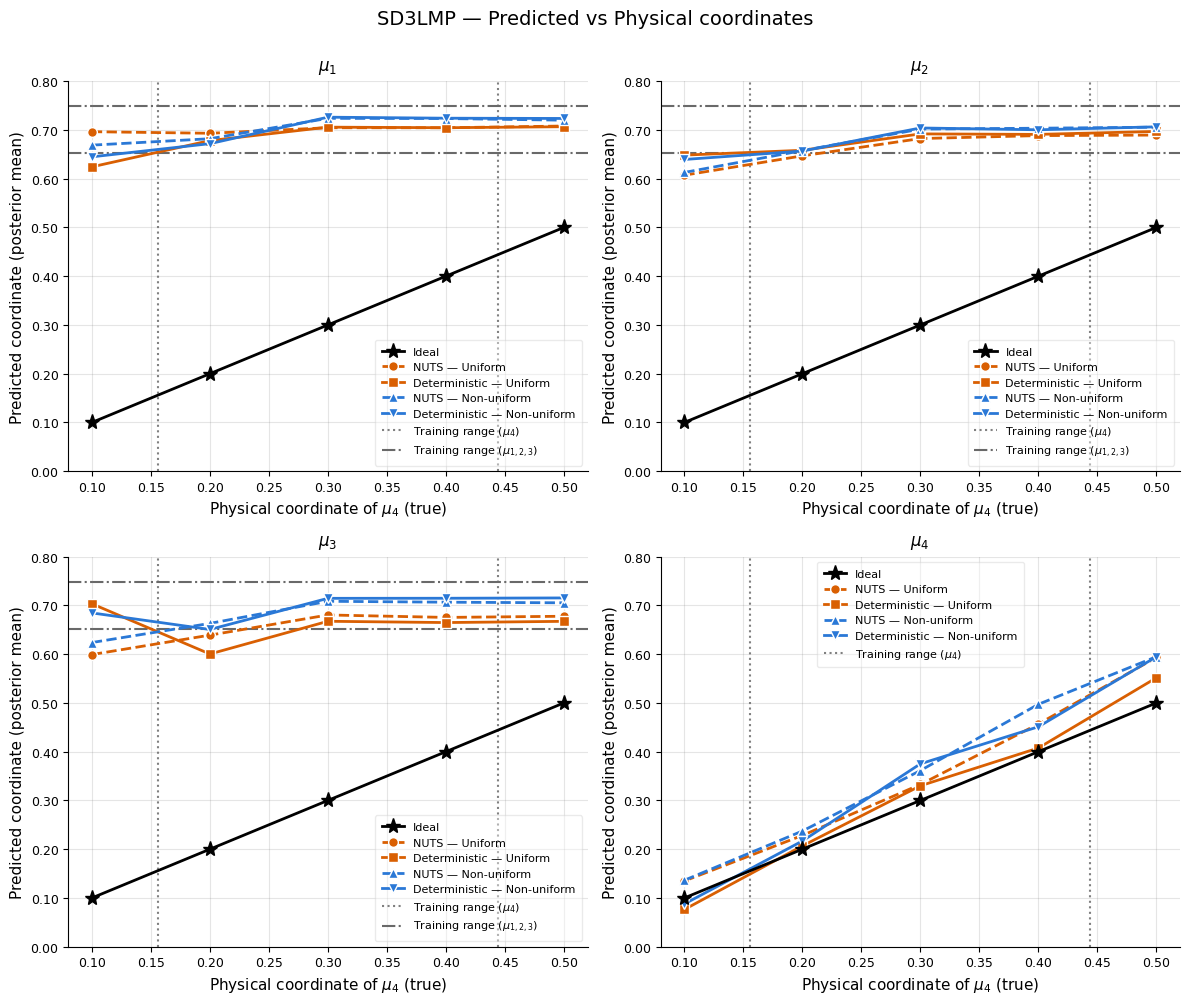

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu_4 = np.array([0.1, 0.2, 0.3, 0.4, 0.5])   # x-axis (swept)

# True/fixed values for mu_1, mu_2, mu_3 (not swept in this experiment)
true_mu_1 = 0.7
true_mu_2 = 0.7   # ASSUMPTION — update if mu_2's true fixed value differs
true_mu_3 = 0.7   # ASSUMPTION — update if mu_3's true fixed value differs

# Training-domain bounds
mu4_train_lo, mu4_train_hi = 0.15600001, 0.44399999   # vertical lines (mu_4 panel)
mu123_train_lo, mu123_train_hi = 0.652, 0.74800001    # horizontal lines (mu_1/2/3 panels)

data = {
    "mu_1": {
        "true": true_mu_1,
        "det_U": np.array([0.62416408, 0.67802448, 0.70558301, 0.7044151,  0.70648898]),
        "det_N": np.array([0.64472366, 0.67173361, 0.72602654, 0.72394773, 0.72340489]),
        "nuts_U": np.array([0.69627341, 0.69303187, 0.70437839, 0.70433558, 0.70790575]),
        "nuts_N": np.array([0.66867534, 0.68187835, 0.72366848, 0.72326257, 0.71987085]),
    },
    "mu_2": {
        "true": true_mu_2,
        "det_U": np.array([0.64824617, 0.6581465,  0.69175023, 0.69075812, 0.69683087]),
        "det_N": np.array([0.63930715, 0.65659318, 0.70391653, 0.70016589, 0.70625086]),
        "nuts_U": np.array([0.60709853, 0.64675623, 0.68220562, 0.68826033, 0.68933522]),
        "nuts_N": np.array([0.61271452, 0.6575295,  0.70160348, 0.70342115, 0.7055373 ]),
    },
    "mu_3": {
        "true": true_mu_3,
        "det_U": np.array([0.70329318, 0.60026858, 0.66738631, 0.66476554, 0.66726677]),
        "det_N": np.array([0.6845457,  0.65057924, 0.71445252, 0.7146039,  0.71525849]),
        "nuts_U": np.array([0.59915048, 0.63896762, 0.68035527, 0.67530578, 0.67770606]),
        "nuts_N": np.array([0.6237893,  0.66303812, 0.70836051, 0.70650615, 0.70526381]),
    },
    "mu_4": {
        "true": None,   # identity line — true value equals x-axis itself
        "det_U": np.array([0.07637274, 0.20673882, 0.33002897, 0.40750385, 0.55152519]),
        "det_N": np.array([0.08769474, 0.21684905, 0.37503993, 0.45108451, 0.59463581]),
        "nuts_U": np.array([0.13478219, 0.22823256, 0.33272861, 0.45681439, 0.59333265]),
        "nuts_N": np.array([0.13630146, 0.23723179, 0.36125658, 0.49716158, 0.59475492]),
    },
}

# ── Style ─────────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform    = "#d95f02"
lw, ms = 2.0, 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

param_labels = {
    "mu_1": r"$\mu_1$ ",
    "mu_2": r"$\mu_2$ ",
    "mu_3": r"$\mu_3$ ",
    "mu_4": r"$\mu_4$ ",
}

for ax, (key, d) in zip(axes, data.items()):

    # Ideal / reference line
    if d["true"] is None:
        # mu_4: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    elif d["true"] ==true_mu_1:
        # mu_1: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    else:
        # mu_1/mu_2/mu_3: horizontal line at the true fixed value
        ax.axhline(y=d["true"], color="black", lw=lw, ls="-", zorder=5,
                    label="Ideal (true value)")

    # Uniform — NUTS (dashed, circle)
    ax.plot(Physical_coordinates_mu_4, d["nuts_U"],
            color=color_uniform, lw=lw, ls="--",
            marker="o", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Uniform")

    # Uniform — Deterministic (solid, square)
    ax.plot(Physical_coordinates_mu_4, d["det_U"],
            color=color_uniform, lw=lw, ls="-",
            marker="s", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Uniform")

    # Non-uniform — NUTS (dashed, triangle up)
    ax.plot(Physical_coordinates_mu_4, d["nuts_N"],
            color=color_nonuniform, lw=lw, ls="--",
            marker="^", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Non-uniform")

    # Non-uniform — Deterministic (solid, triangle down)
    ax.plot(Physical_coordinates_mu_4, d["det_N"],
            color=color_nonuniform, lw=lw, ls="-",
            marker="v", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Non-uniform")

    # ── Training-domain reference lines ────────────────────────────────────
    # Vertical lines: training range of mu_4 — shown in all panels, since the
    # x-axis (physical coordinate of mu_4) is shared across all four subplots.
    ax.axvline(x=mu4_train_lo, color="gray", lw=1.5, ls=":", zorder=1,
                label="Training range ($\\mu_4$)")
    ax.axvline(x=mu4_train_hi, color="gray", lw=1.5, ls=":", zorder=1)
    
    

    if key != "mu_4":
        # Horizontal lines: training range of mu_1/mu_2/mu_3 (y-axis is predicted value)
        ax.axhline(y=mu123_train_lo, color="dimgray", lw=1.5, ls="-.", zorder=1,
                    label="Training range ($\\mu_{1,2,3}$)")
        ax.axhline(y=mu123_train_hi, color="dimgray", lw=1.5, ls="-.", zorder=1)

    # ── Formatting per subplot ──────────────────────────────────────────────
    ax.set_xlabel(r"Physical coordinate of $\mu_4$ (true)", fontsize=11)
    ax.set_ylabel("Predicted coordinate (posterior mean)", fontsize=11)
    ax.set_title(param_labels[key], fontsize=12, pad=8)

    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.tick_params(labelsize=9)

    ax.set_ylim(0, 0.8)
    ax.grid(color="gray", alpha=0.2, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, framealpha=0.4, loc="best", borderpad=0.6)

fig.suptitle("SD3LMP — Predicted vs Physical coordinates",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig("predicted_vs_physical_grid.pdf", bbox_inches="tight", dpi=150)
plt.savefig("predicted_vs_physical_grid.png", bbox_inches="tight", dpi=150)
plt.show()

# 1000 warmup , 1000 samples

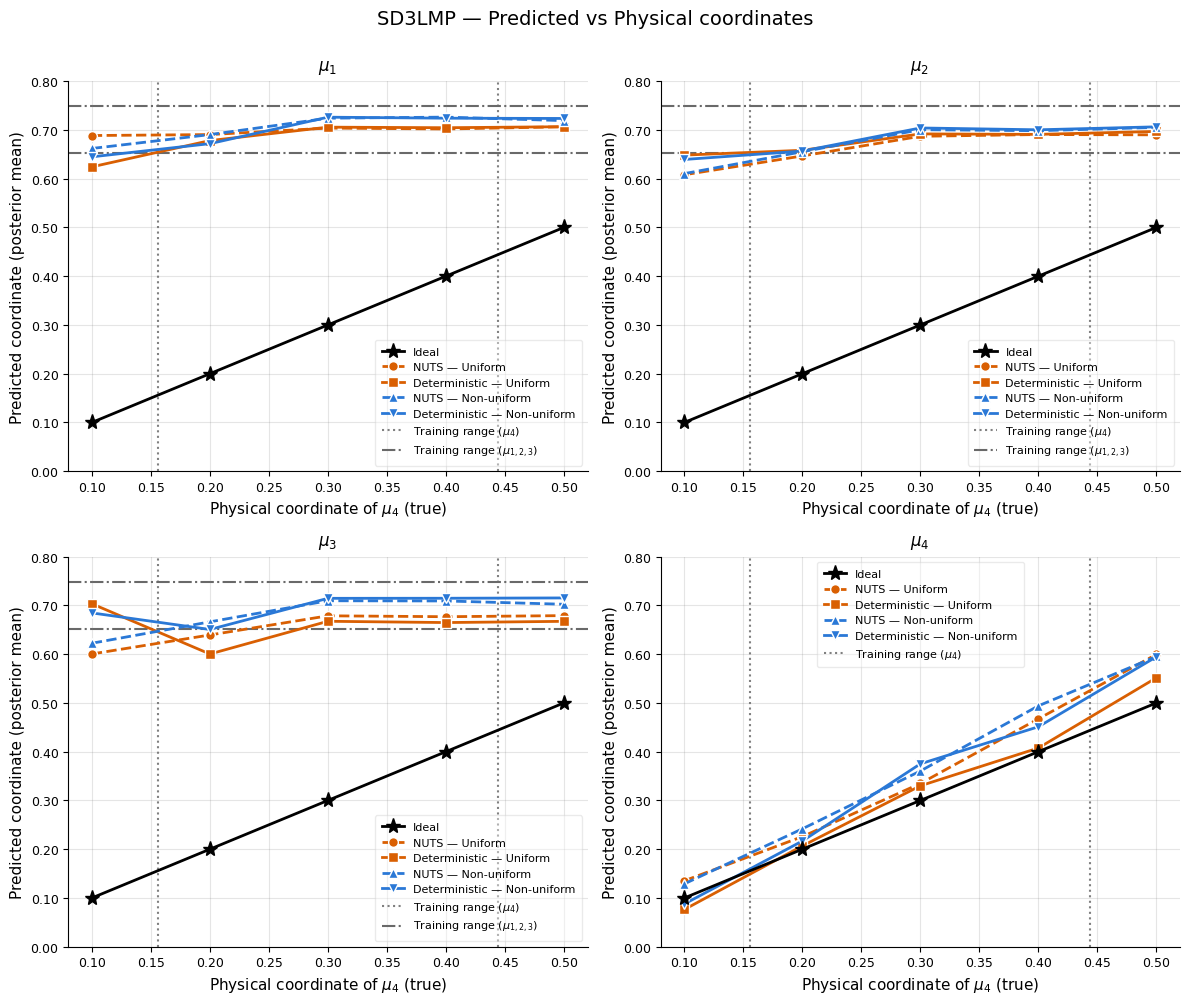

In [47]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu_4 = np.array([0.1, 0.2, 0.3, 0.4, 0.5])   # x-axis (swept)

# True/fixed values for mu_1, mu_2, mu_3 (not swept in this experiment)
true_mu_1 = 0.7
true_mu_2 = 0.7   # ASSUMPTION — update if mu_2's true fixed value differs
true_mu_3 = 0.7   # ASSUMPTION — update if mu_3's true fixed value differs

# Training-domain bounds
mu4_train_lo, mu4_train_hi = 0.15600001, 0.44399999   # vertical lines (mu_4 panel)
mu123_train_lo, mu123_train_hi = 0.652, 0.74800001    # horizontal lines (mu_1/2/3 panels)

data = {
    "mu_1": {
        "true": true_mu_1,
        "det_U": np.array([0.62416408, 0.67802448, 0.70558301, 0.7044151,  0.70648898]),
        "det_N": np.array([0.64472366, 0.67173361, 0.72602654, 0.72394773, 0.72340489]),
        "nuts_U": np.array([0.68840066, 0.69036884, 0.70367529, 0.70183458, 0.70632644]),
        "nuts_N": np.array([0.6618574 , 0.690324  , 0.72392767, 0.72617345, 0.71896585]),
    },
    "mu_2": {
        "true": true_mu_2,
        "det_U": np.array([0.64824617, 0.6581465,  0.69175023, 0.69075812, 0.69683087]),
        "det_N": np.array([0.63930715, 0.65659318, 0.70391653, 0.70016589, 0.70625086]),
        "nuts_U": np.array([0.60794959, 0.64656277, 0.68684729, 0.69044918, 0.68983309]),
        "nuts_N": np.array([0.61032678, 0.65521676,  0.7003549 , 0.69828704, 0.70507054]),
    },
    "mu_3": {
        "true": true_mu_3,
        "det_U": np.array([0.70329318, 0.60026858, 0.66738631, 0.66476554, 0.66726677]),
        "det_N": np.array([0.6845457,  0.65057924, 0.71445252, 0.7146039,  0.71525849]),
        "nuts_U": np.array([0.600407  , 0.63931557, 0.67860134, 0.67676135, 0.67899316]),
        "nuts_N": np.array([0.62234769,  0.66621802, 0.70945131, 0.70904914, 0.70226942]),
    },
    "mu_4": {
        "true": None,   # identity line — true value equals x-axis itself
        "det_U": np.array([0.07637274, 0.20673882, 0.33002897, 0.40750385, 0.55152519]),
        "det_N": np.array([0.08769474, 0.21684905, 0.37503993, 0.45108451, 0.59463581]),
        "nuts_U": np.array([0.13528607, 0.22582254, 0.33474905, 0.46734729, 0.59951355]),
        "nuts_N": np.array([0.12900661, 0.2417887 , 0.36032971, 0.49394806, 0.59521023]),
    },
}

# ── Style ─────────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform    = "#d95f02"
lw, ms = 2.0, 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

param_labels = {
    "mu_1": r"$\mu_1$ ",
    "mu_2": r"$\mu_2$ ",
    "mu_3": r"$\mu_3$ ",
    "mu_4": r"$\mu_4$ ",
}

for ax, (key, d) in zip(axes, data.items()):

    # Ideal / reference line
    if d["true"] is None:
        # mu_4: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    elif d["true"] ==true_mu_1:
        # mu_1: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    else:
        # mu_1/mu_2/mu_3: horizontal line at the true fixed value
        ax.axhline(y=d["true"], color="black", lw=lw, ls="-", zorder=5,
                    label="Ideal (true value)")

    # Uniform — NUTS (dashed, circle)
    ax.plot(Physical_coordinates_mu_4, d["nuts_U"],
            color=color_uniform, lw=lw, ls="--",
            marker="o", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Uniform")

    # Uniform — Deterministic (solid, square)
    ax.plot(Physical_coordinates_mu_4, d["det_U"],
            color=color_uniform, lw=lw, ls="-",
            marker="s", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Uniform")

    # Non-uniform — NUTS (dashed, triangle up)
    ax.plot(Physical_coordinates_mu_4, d["nuts_N"],
            color=color_nonuniform, lw=lw, ls="--",
            marker="^", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Non-uniform")

    # Non-uniform — Deterministic (solid, triangle down)
    ax.plot(Physical_coordinates_mu_4, d["det_N"],
            color=color_nonuniform, lw=lw, ls="-",
            marker="v", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Non-uniform")

    # ── Training-domain reference lines ────────────────────────────────────
    # Vertical lines: training range of mu_4 — shown in all panels, since the
    # x-axis (physical coordinate of mu_4) is shared across all four subplots.
    ax.axvline(x=mu4_train_lo, color="gray", lw=1.5, ls=":", zorder=1,
                label="Training range ($\\mu_4$)")
    ax.axvline(x=mu4_train_hi, color="gray", lw=1.5, ls=":", zorder=1)
    
    

    if key != "mu_4":
        # Horizontal lines: training range of mu_1/mu_2/mu_3 (y-axis is predicted value)
        ax.axhline(y=mu123_train_lo, color="dimgray", lw=1.5, ls="-.", zorder=1,
                    label="Training range ($\\mu_{1,2,3}$)")
        ax.axhline(y=mu123_train_hi, color="dimgray", lw=1.5, ls="-.", zorder=1)

    # ── Formatting per subplot ──────────────────────────────────────────────
    ax.set_xlabel(r"Physical coordinate of $\mu_4$ (true)", fontsize=11)
    ax.set_ylabel("Predicted coordinate (posterior mean)", fontsize=11)
    ax.set_title(param_labels[key], fontsize=12, pad=8)

    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.tick_params(labelsize=9)

    ax.set_ylim(0, 0.8)
    ax.grid(color="gray", alpha=0.2, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, framealpha=0.4, loc="best", borderpad=0.6)

fig.suptitle("SD3LMP — Predicted vs Physical coordinates",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig("predicted_vs_physical_grid.pdf", bbox_inches="tight", dpi=150)
plt.savefig("predicted_vs_physical_grid.png", bbox_inches="tight", dpi=150)
plt.show()

# Plot for 1% Noise

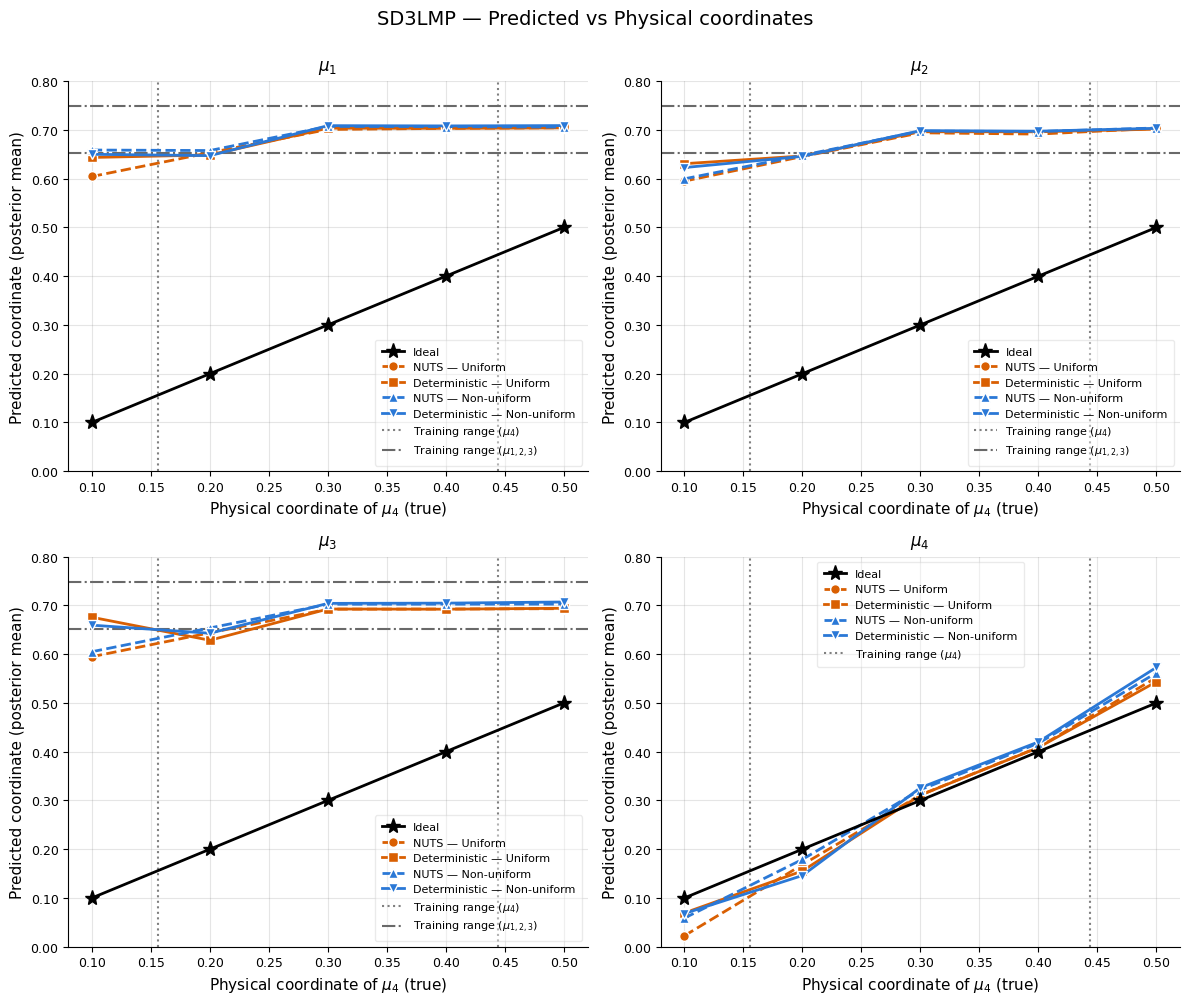

In [48]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu_4 = np.array([0.1, 0.2, 0.3, 0.4, 0.5])   # x-axis (swept)
Physical_coordinates_mu_1 = np.array([0.7, 0.7, 0.7, 0.7, 0.7])   # y-axis (fixed)

# True/fixed values for mu_1, mu_2, mu_3 (not swept in this experiment)
true_mu_1 = 0.7
true_mu_2 = 0.7   # ASSUMPTION — update if mu_2's true fixed value differs
true_mu_3 = 0.7   # ASSUMPTION — update if mu_3's true fixed value differs

# Training-domain bounds
mu4_train_lo, mu4_train_hi = 0.15600001, 0.44399999   # vertical lines (mu_4 panel)
mu123_train_lo, mu123_train_hi = 0.652, 0.74800001    # horizontal lines (mu_1/2/3 panels)

data = {
    "mu_1": {
        "true": true_mu_1,
        "det_U": np.array([0.64341805, 0.64854702, 0.70348763, 0.7031292 ,  0.70408839]),
        "nuts_U": np.array([0.60440537, 0.65324689, 0.70084519, 0.70311915, 0.70439897]),
        "det_N": np.array([0.64990184, 0.64716085, 0.70866431, 0.70811914, 0.70879862]),
        "nuts_N": np.array([0.658643  , 0.65763874, 0.70703966, 0.70669358, 0.70568389]),
    },
    "mu_2": {
        "true": true_mu_2,
        "det_U": np.array([0.63063078, 0.64648086,  0.69608622, 0.69605206, 0.70151166]),
        "nuts_U": np.array([0.5948632 , 0.64529666, 0.69398692, 0.6913404 , 0.70322917]),
        "det_N": np.array([0.62272084, 0.64569064, 0.69846331, 0.69733863, 0.70322917]),
        "nuts_N": np.array([0.59962012, 0.64790034,  0.69742235, 0.69663895, 0.70386941]),
    },
    "mu_3": {
        "true": true_mu_3,
        "det_U": np.array([0.67566081, 0.62843944, 0.69254881, 0.69217439, 0.69406081]),
        "nuts_U": np.array([0.59475961,  0.64371645, 0.69222324, 0.69250947,  0.69322897]),
        "det_N": np.array([0.65943999, 0.64282576, 0.70409088, 0.70459409, 0.7069399 ]),
        "nuts_N": np.array([0.60498961,  0.65367494, 0.70233871, 0.70246701, 0.70259331]),
    },
    "mu_4": {
        "true": None,   # identity line — true value equals x-axis itself
        "det_U": np.array([0.06928166, 0.15536724, 0.31081573, 0.40840335, 0.54339242]),
        "nuts_U": np.array([0.02251971, 0.16816183, 0.3112093 , 0.40879791, 0.55203231]),
        "det_N": np.array([0.06803776, 0.1459926 , 0.32607697, 0.41999859, 0.57277906]),
        "nuts_N": np.array([0.05866086, 0.17904024, 0.32197505, 0.41726085, 0.56160807]),
    },
}

# ── Style ─────────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform    = "#d95f02"
lw, ms = 2.0, 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

param_labels = {
    "mu_1": r"$\mu_1$ ",
    "mu_2": r"$\mu_2$ ",
    "mu_3": r"$\mu_3$ ",
    "mu_4": r"$\mu_4$ ",
}

for ax, (key, d) in zip(axes, data.items()):

    # Ideal / reference line
    if d["true"] is None:
        # mu_4: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
        
    elif d["true"] ==true_mu_1:
        # mu_1: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    else:
        # mu_1/mu_2/mu_3: horizontal line at the true fixed value
        ax.axhline(y=d["true"], color="black", lw=lw, ls="-", zorder=5,
                    label="Ideal (true value)")

    # Uniform — NUTS (dashed, circle)
    ax.plot(Physical_coordinates_mu_4, d["nuts_U"],
            color=color_uniform, lw=lw, ls="--",
            marker="o", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Uniform")

    # Uniform — Deterministic (solid, square)
    ax.plot(Physical_coordinates_mu_4, d["det_U"],
            color=color_uniform, lw=lw, ls="-",
            marker="s", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Uniform")

    # Non-uniform — NUTS (dashed, triangle up)
    ax.plot(Physical_coordinates_mu_4, d["nuts_N"],
            color=color_nonuniform, lw=lw, ls="--",
            marker="^", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Non-uniform")

    # Non-uniform — Deterministic (solid, triangle down)
    ax.plot(Physical_coordinates_mu_4, d["det_N"],
            color=color_nonuniform, lw=lw, ls="-",
            marker="v", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Non-uniform")

    # ── Training-domain reference lines ────────────────────────────────────
    # Vertical lines: training range of mu_4 — shown in all panels, since the
    # x-axis (physical coordinate of mu_4) is shared across all four subplots.
    ax.axvline(x=mu4_train_lo, color="gray", lw=1.5, ls=":", zorder=1,
                label="Training range ($\\mu_4$)")
    ax.axvline(x=mu4_train_hi, color="gray", lw=1.5, ls=":", zorder=1)

    if key != "mu_4":
        # Horizontal lines: training range of mu_1/mu_2/mu_3 (y-axis is predicted value)
        ax.axhline(y=mu123_train_lo, color="dimgray", lw=1.5, ls="-.", zorder=1,
                    label="Training range ($\\mu_{1,2,3}$)")
        ax.axhline(y=mu123_train_hi, color="dimgray", lw=1.5, ls="-.", zorder=1)

    # ── Formatting per subplot ──────────────────────────────────────────────
    ax.set_xlabel(r"Physical coordinate of $\mu_4$ (true)", fontsize=11)
    ax.set_ylabel("Predicted coordinate (posterior mean)", fontsize=11)
    ax.set_title(param_labels[key], fontsize=12, pad=8)

    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.tick_params(labelsize=9)
    
    ax.set_ylim(0, 0.8)
    ax.grid(color="gray", alpha=0.2, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, framealpha=0.4, loc="best", borderpad=0.6)

fig.suptitle("SD3LMP — Predicted vs Physical coordinates",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig("predicted_vs_physical_grid.pdf", bbox_inches="tight", dpi=150)
plt.savefig("predicted_vs_physical_grid.png", bbox_inches="tight", dpi=150)
plt.show()

# 1000 warmup , 1000 samples

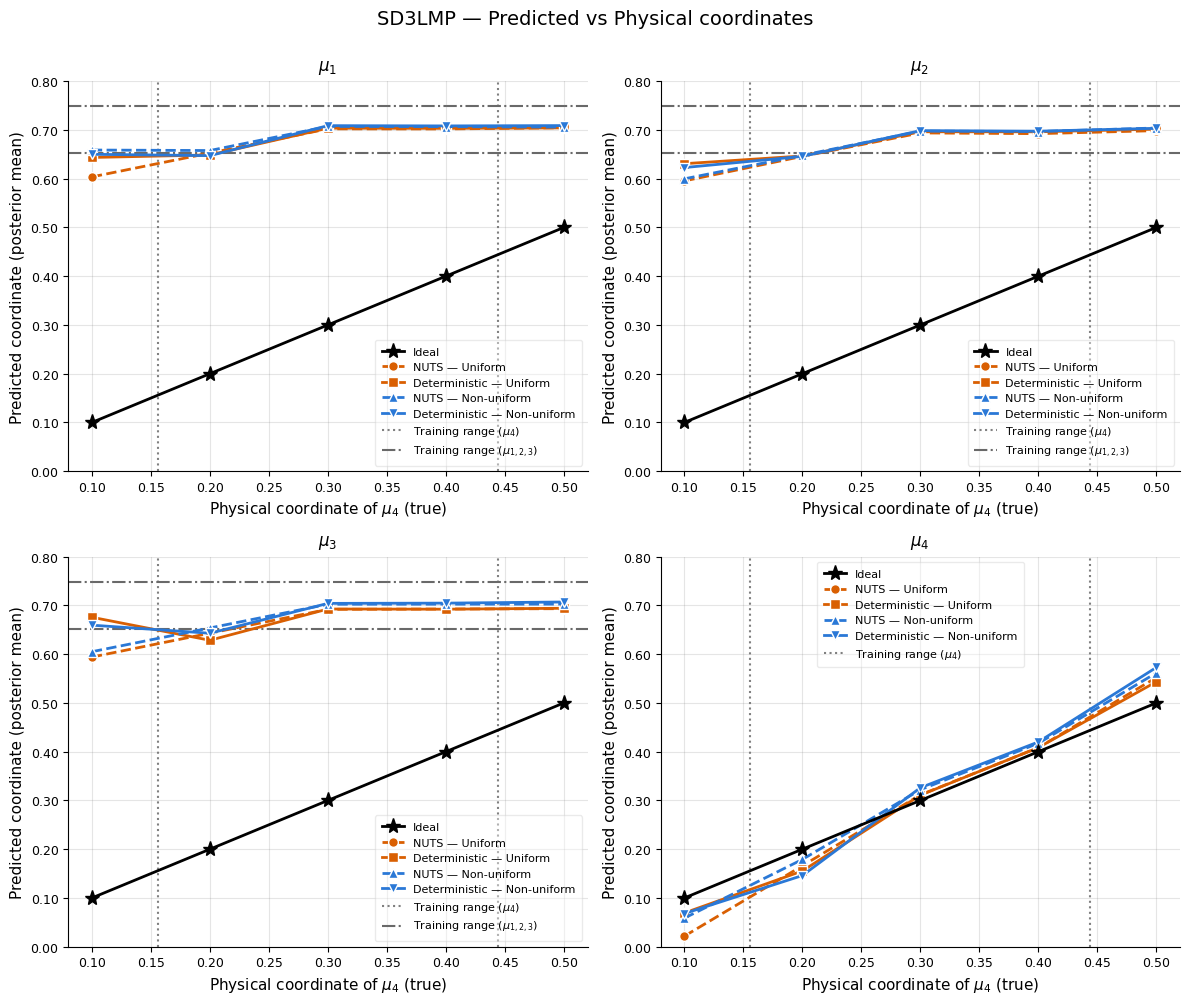

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ── Data ────────────────────────────────────────────────────────────────────
Physical_coordinates_mu_4 = np.array([0.1, 0.2, 0.3, 0.4, 0.5])   # x-axis (swept)
Physical_coordinates_mu_1 = np.array([0.7, 0.7, 0.7, 0.7, 0.7])   # y-axis (fixed)

# True/fixed values for mu_1, mu_2, mu_3 (not swept in this experiment)
true_mu_1 = 0.7
true_mu_2 = 0.7   # ASSUMPTION — update if mu_2's true fixed value differs
true_mu_3 = 0.7   # ASSUMPTION — update if mu_3's true fixed value differs

# Training-domain bounds
mu4_train_lo, mu4_train_hi = 0.15600001, 0.44399999   # vertical lines (mu_4 panel)
mu123_train_lo, mu123_train_hi = 0.652, 0.74800001    # horizontal lines (mu_1/2/3 panels)

data = {
    "mu_1": {
        "true": true_mu_1,
        "det_U": np.array([0.64341805, 0.64854702, 0.70348763, 0.7031292 ,  0.70408839]),
        "nuts_U": np.array([0.60363397, 0.65245991, 0.7020974 , 0.70188288, 0.70439897]),
        "det_N": np.array([0.64990184, 0.64716085, 0.70866431, 0.70811914, 0.70879862]),
        "nuts_N": np.array([0.658643  , 0.65763874, 0.70703966, 0.70669358, 0.70568389]),
    },
    "mu_2": {
        "true": true_mu_2,
        "det_U": np.array([0.63063078, 0.64648086,  0.69608622, 0.69605206, 0.70151166]),
        "nuts_U": np.array([0.59533947 ,0.64566563, 0.69374273, 0.69225187 , 0.69843969]),
        "det_N": np.array([0.62272084, 0.64569064, 0.69846331, 0.69733863, 0.70322917]),
        "nuts_N": np.array([0.59962012, 0.64790034,  0.69742235, 0.69663895, 0.70386941]),
    },
    "mu_3": {
        "true": true_mu_3,
        "det_U": np.array([0.67566081, 0.62843944, 0.69254881, 0.69217439, 0.69406081]),
        "nuts_U": np.array([0.59403535,  0.64290799, 0.69190079,0.6925113 ,  0.69322897]),
        "det_N": np.array([0.65943999, 0.64282576, 0.70409088, 0.70459409, 0.7069399 ]),
        "nuts_N": np.array([0.60498961,  0.65367494, 0.70233871, 0.70246701, 0.70259331]),
    },
    "mu_4": {
        "true": None,   # identity line — true value equals x-axis itself
        "det_U": np.array([0.06928166, 0.15536724, 0.31081573, 0.40840335, 0.54339242]),
        "nuts_U": np.array([0.02171344, 0.16595151, 0.31140528 , 0.4082607 , 0.55203231]),
        "det_N": np.array([0.06803776, 0.1459926 , 0.32607697, 0.41999859, 0.57277906]),
        "nuts_N": np.array([0.05866086, 0.17904024, 0.32197505, 0.41726085, 0.56160807]),
    },
}

# ── Style ─────────────────────────────────────────────────────────────────────
color_nonuniform = "#2a78d6"
color_uniform    = "#d95f02"
lw, ms = 2.0, 7

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

param_labels = {
    "mu_1": r"$\mu_1$ ",
    "mu_2": r"$\mu_2$ ",
    "mu_3": r"$\mu_3$ ",
    "mu_4": r"$\mu_4$ ",
}

for ax, (key, d) in zip(axes, data.items()):

    # Ideal / reference line
    if d["true"] is None:
        # mu_4: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
        
    elif d["true"] ==true_mu_1:
        # mu_1: identity line y = x
        ax.plot(Physical_coordinates_mu_4, Physical_coordinates_mu_4,
                 color="black", lw=lw, ls="-",
                 marker="*", markersize=ms + 4,
                 label="Ideal", zorder=5)
    else:
        # mu_1/mu_2/mu_3: horizontal line at the true fixed value
        ax.axhline(y=d["true"], color="black", lw=lw, ls="-", zorder=5,
                    label="Ideal (true value)")

    # Uniform — NUTS (dashed, circle)
    ax.plot(Physical_coordinates_mu_4, d["nuts_U"],
            color=color_uniform, lw=lw, ls="--",
            marker="o", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Uniform")

    # Uniform — Deterministic (solid, square)
    ax.plot(Physical_coordinates_mu_4, d["det_U"],
            color=color_uniform, lw=lw, ls="-",
            marker="s", markersize=ms,
            markerfacecolor=color_uniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Uniform")

    # Non-uniform — NUTS (dashed, triangle up)
    ax.plot(Physical_coordinates_mu_4, d["nuts_N"],
            color=color_nonuniform, lw=lw, ls="--",
            marker="^", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="NUTS — Non-uniform")

    # Non-uniform — Deterministic (solid, triangle down)
    ax.plot(Physical_coordinates_mu_4, d["det_N"],
            color=color_nonuniform, lw=lw, ls="-",
            marker="v", markersize=ms,
            markerfacecolor=color_nonuniform, markeredgecolor="white", markeredgewidth=1.0,
            label="Deterministic — Non-uniform")

    # ── Training-domain reference lines ────────────────────────────────────
    # Vertical lines: training range of mu_4 — shown in all panels, since the
    # x-axis (physical coordinate of mu_4) is shared across all four subplots.
    ax.axvline(x=mu4_train_lo, color="gray", lw=1.5, ls=":", zorder=1,
                label="Training range ($\\mu_4$)")
    ax.axvline(x=mu4_train_hi, color="gray", lw=1.5, ls=":", zorder=1)

    if key != "mu_4":
        # Horizontal lines: training range of mu_1/mu_2/mu_3 (y-axis is predicted value)
        ax.axhline(y=mu123_train_lo, color="dimgray", lw=1.5, ls="-.", zorder=1,
                    label="Training range ($\\mu_{1,2,3}$)")
        ax.axhline(y=mu123_train_hi, color="dimgray", lw=1.5, ls="-.", zorder=1)

    # ── Formatting per subplot ──────────────────────────────────────────────
    ax.set_xlabel(r"Physical coordinate of $\mu_4$ (true)", fontsize=11)
    ax.set_ylabel("Predicted coordinate (posterior mean)", fontsize=11)
    ax.set_title(param_labels[key], fontsize=12, pad=8)

    ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter("%.2f"))
    ax.tick_params(labelsize=9)
    
    ax.set_ylim(0, 0.8)
    ax.grid(color="gray", alpha=0.2, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, framealpha=0.4, loc="best", borderpad=0.6)

fig.suptitle("SD3LMP — Predicted vs Physical coordinates",
             fontsize=14, y=1.00)
plt.tight_layout()
plt.savefig("predicted_vs_physical_grid.pdf", bbox_inches="tight", dpi=150)
plt.savefig("predicted_vs_physical_grid.png", bbox_inches="tight", dpi=150)
plt.show()

# 0.1
Sigma =np.array([50.7140,  6.9305,  3.6982, 1.6705])
# 0.2
Sigma =np.array([6.5783 ,  3.9123,  2.9081, 2.1935])
# 0.3
Sigma =np.array([7.0672 ,  4.5728,  3.1569, 2.1185])
# 0.4
Sigma =np.array([8.0614 ,  4.6329,  3.1128, 2.5203])
# 0.5
Sigma =np.array([8.5476 ,  4.6538,  2.9150, 1.2606])

[0.15114179 0.25149634 0.33399389 0.4333745 ]


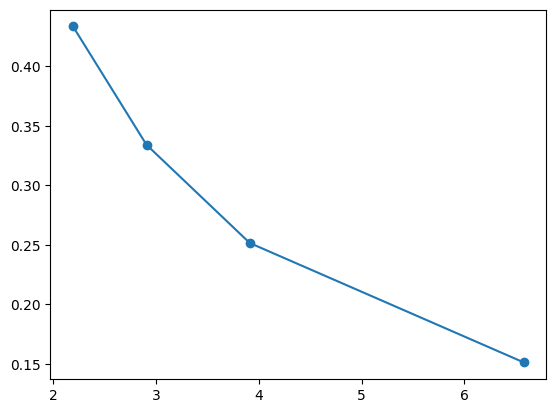

In [56]:
Sigma =np.array([6.5783 ,  3.9123,  2.9081, 2.1935])
y = Sigma/ (((1/2)**2 + Sigma**2))
print(y)
plt.plot(Sigma, y, marker='o')

# 0.1 tensor()5.0952


tensor(5.2761)     #0.2 tensor(0.5518)

tensor(0.4963) ,  #03 tensor(0.0499)

tensor(0.0482),  # 0.4 tensor(0.0384)

tensor(0.0356) # 0.5 tensor(0.2140)

tensor(0.2182)

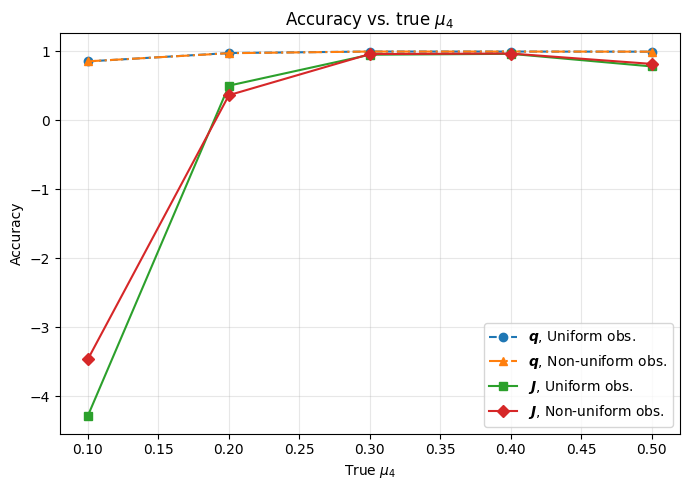

In [57]:
# 0.1 
obs_mu_4          = np.array([0.1,0.2,0.3,0.4,0.5])
f_accuracy        = np.array([0.8656, 0.9777, 0.9979, 0.9978, 0.9960])
f_accuracy_obs_U  = np.array([0.8547, 0.9759, 0.9977, 0.9975, 0.9955])
f_accuracy_obs_N  = np.array([0.8558, 0.9734, 0.9975, 0.9974, 0.9959])
J_accuracy        = np.array([-4.0952, 0.4482, 0.9501, 0.9616, 0.7860])
J_accuracy_obs_U  = np.array([-4.2761, 0.5037, 0.9518, 0.9644, 0.7818])
J_accuracy_obs_N  = np.array([-3.4577, 0.3656, 0.9612, 0.9686,0.8183])


plt.figure(figsize=(7,5))

plt.plot(obs_mu_4, f_accuracy_obs_U, linestyle='--', marker='o', color='tab:blue',
         label=r'$\boldsymbol{q}$, Uniform obs.')
plt.plot(obs_mu_4, f_accuracy_obs_N, linestyle='-.', marker='^', color='tab:orange',
         label=r'$\boldsymbol{q}$, Non-uniform obs.')

plt.plot(obs_mu_4, J_accuracy_obs_U, linestyle='-', marker='s', color='tab:green',
         label=r'$\boldsymbol{J}$, Uniform obs.')
plt.plot(obs_mu_4, J_accuracy_obs_N, linestyle='-', marker='D', color='tab:red',
         label=r'$\boldsymbol{J}$, Non-uniform obs.')

plt.xlabel(r"True $\mu_4$")
plt.ylabel("Accuracy")
plt.title(r"Accuracy vs. true $\mu_4$")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()